In [1]:
import os
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

In [2]:
# locate workspace local
current = Path.cwd().resolve()
if (current / "src").exists():
    project_root = current
elif (current.parent / "src").exists():
    project_root = current.parent
else:
    project_root = Path(r"F:\Learning\HUST_DOCUMENTS\MI3390-DoAn2\workspace")

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

print(f"Project root: {project_root}")

Project root: F:\Learning\HUST_DOCUMENTS\MI3390-DoAn2\workspace


In [4]:
from src.utils.spark_utils import get_spark_session
spark = get_spark_session("LaptopPricing_EDA")
print(f"Spark Version: {spark.version}")

Spark Version: 4.2.1


---
# OVERVIEW
---

In [5]:
silver_path = str(project_root / "data" / "processed" / "silver_layer")
print(f"Đọc dữ liệu từ: {silver_path}")

df_spark = spark.read.parquet(silver_path)

print(f"Tổng số bản ghi: {df_spark.count():,}")
df_spark.printSchema()

Đọc dữ liệu từ: F:\Learning\HUST_DOCUMENTS\MI3390-DoAn2\workspace\data\processed\silver_layer
Tổng số bản ghi: 10,143
root
 |-- post_id: string (nullable = true)
 |-- target_price: float (nullable = true)
 |-- raw_cpu: string (nullable = true)
 |-- raw_ram: string (nullable = true)
 |-- raw_hard_drive: string (nullable = true)
 |-- raw_hard_drive_type: string (nullable = true)
 |-- pc_brand: integer (nullable = true)
 |-- pc_cpu: integer (nullable = true)
 |-- pc_ram: integer (nullable = true)
 |-- laptop_screen_size: integer (nullable = true)
 |-- elt_condition: integer (nullable = true)
 |-- elt_origin: integer (nullable = true)
 |-- elt_warranty: integer (nullable = true)
 |-- region_name: string (nullable = true)
 |-- ward_name: string (nullable = true)
 |-- seller_rating: float (nullable = true)
 |-- seller_sold_count: integer (nullable = true)
 |-- crawled_at: timestamp (nullable = true)
 |-- url: string (nullable = true)
 |-- is_seller_rating_missing: integer (nullable = true)
 

In [6]:
df = df_spark.toPandas()
print(f"Kích thước DataFrame Pandas: {df.shape}")
display(df.head())

Kích thước DataFrame Pandas: (10143, 52)


,post_id,target_price,raw_cpu,raw_ram,raw_hard_drive,raw_hard_drive_type,pc_brand,pc_cpu,pc_ram,laptop_screen_size,...,battery_condition,warranty_months,warranty_type,has_warranty,is_upgraded,repair_status,year_production,year_purchase,bundles,has_bundle
0,58129676,3400000.0,Intel Core i5,8 GB,256 GB,SSD,6,7.0,6.0,4.0,...,NaN,3.0,cua_hang,1,NaN,original,NaN,NaN,cặp đựng laptop trị giá 200k,1
1,88402908,3700000.0,Intel Core i5,8 GB,256 GB,SSD,5,7.0,6.0,4.0,...,NaN,3.0,cua_hang,1,NaN,original,NaN,NaN,cặp đựng laptop trị giá 200k,1
2,89474040,4900000.0,Intel Core i7,8 GB,256 GB,SSD,5,8.0,6.0,4.0,...,NaN,3.0,cua_hang,1,NaN,original,NaN,NaN,cặp đựng laptop trị giá 200k cam kết của cửa h...,1
3,95478396,11990000.0,Intel Core i7,16 GB,512 GB,SSD,5,8.0,7.0,4.0,...,NaN,NaN,cua_hang,1,NaN,NaN,NaN,NaN,túi chống sốc-chuột và lót chuột xịn —“đạo đức...,1
4,99812342,9000000.0,Intel Core i7,16 GB,256 GB,SSD,5,8.0,7.0,5.0,...,NaN,3.0,cua_hang,1,NaN,original,NaN,NaN,balo đựng laptop cam kết của cửa hàng: 📌máy ca...,1


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10143 entries, 0 to 10142
Data columns (total 52 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   post_id                   10143 non-null  str           
 1   target_price              10143 non-null  float32       
 2   raw_cpu                   9580 non-null   str           
 3   raw_ram                   9718 non-null   str           
 4   raw_hard_drive            9309 non-null   str           
 5   raw_hard_drive_type       9079 non-null   str           
 6   pc_brand                  10143 non-null  int32         
 7   pc_cpu                    9580 non-null   float64       
 8   pc_ram                    9718 non-null   float64       
 9   laptop_screen_size        8249 non-null   float64       
 10  elt_condition             10143 non-null  int32         
 11  elt_origin                3460 non-null   float64       
 12  elt_warranty              101

In [8]:
df.describe()

,target_price,pc_brand,pc_cpu,pc_ram,laptop_screen_size,elt_condition,elt_origin,elt_warranty,seller_rating,seller_sold_count,...,condition_pct,battery_pct,battery_cycles,battery_hours,warranty_months,has_warranty,is_upgraded,year_production,year_purchase,has_bundle
count,10143.0,10143.000000,9580.000000,9718.000000,8249.000000,10143.000000,3460.000000,10143.000000,7739.000000,10143.000000,...,227.000000,658.000000,31.000000,606.000000,2939.000000,10143.000000,208.0,159.000000,15.000000,10143.000000
mean,11165325.0,5.538007,10.059395,6.545688,4.435204,1.977620,5.358671,0.974662,4.722794,231.827960,...,97.299559,94.727964,100.451613,3.228053,3.588976,0.538401,1.0,2021.226415,2024.000000,0.246968
min,0.0,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,-1.000000,1.000000,0.000000,...,80.000000,38.000000,3.000000,1.000000,0.000000,0.000000,1.0,2012.000000,2021.000000,0.000000
25%,4500000.0,4.000000,7.000000,6.000000,4.000000,2.000000,1.000000,-1.000000,4.600000,7.000000,...,97.000000,90.000000,10.000000,2.000000,1.000000,0.000000,1.0,2020.000000,2023.000000,0.000000
50%,8100000.0,5.000000,8.000000,6.000000,4.000000,2.000000,7.000000,-1.000000,4.900000,47.000000,...,98.000000,99.000000,72.000000,3.000000,3.000000,1.000000,1.0,2021.000000,2024.000000,0.000000
75%,14800000.0,6.000000,10.000000,7.000000,5.000000,2.000000,8.000000,3.000000,5.000000,270.000000,...,99.000000,100.000000,170.500000,4.000000,3.000000,1.000000,1.0,2023.000000,2026.000000,0.000000
max,149000000.0,20.000000,54.000000,29.000000,8.000000,3.000000,10.000000,8.000000,5.000000,32534.000000,...,100.000000,100.000000,390.000000,16.000000,36.000000,1.000000,1.0,2026.000000,2026.000000,1.000000
std,10213197.0,3.131810,6.008756,1.635110,0.636508,0.200551,3.102838,2.694138,0.501958,632.282301,...,2.632027,7.621398,106.863414,1.449675,3.382144,0.498548,0.0,2.365160,1.889822,0.431269


In [9]:
missing_pct = (df.isnull().sum() / len(df) * 100).sort_values(ascending=False)
missing_summary = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing Percentage (%)': missing_pct
}).sort_values(by='Missing Percentage (%)', ascending=False)

print("Top 15 cột thiếu dữ liệu nhiều nhất:")
display(missing_summary[missing_summary['Missing Percentage (%)'] > 0].head(15))

Top 15 cột thiếu dữ liệu nhiều nhất:


,Missing Count,Missing Percentage (%)
year_purchase,10128,99.852115
battery_cycles,10112,99.694371
is_new_seal,10025,98.836636
year_production,9984,98.432416
is_upgraded,9935,97.949325
condition_pct,9916,97.762003
origin_country,9689,95.524007
battery_hours,9537,94.025436
battery_pct,9485,93.512767
battery_condition,9287,91.560682


---
# TARGET VARIABLE
---

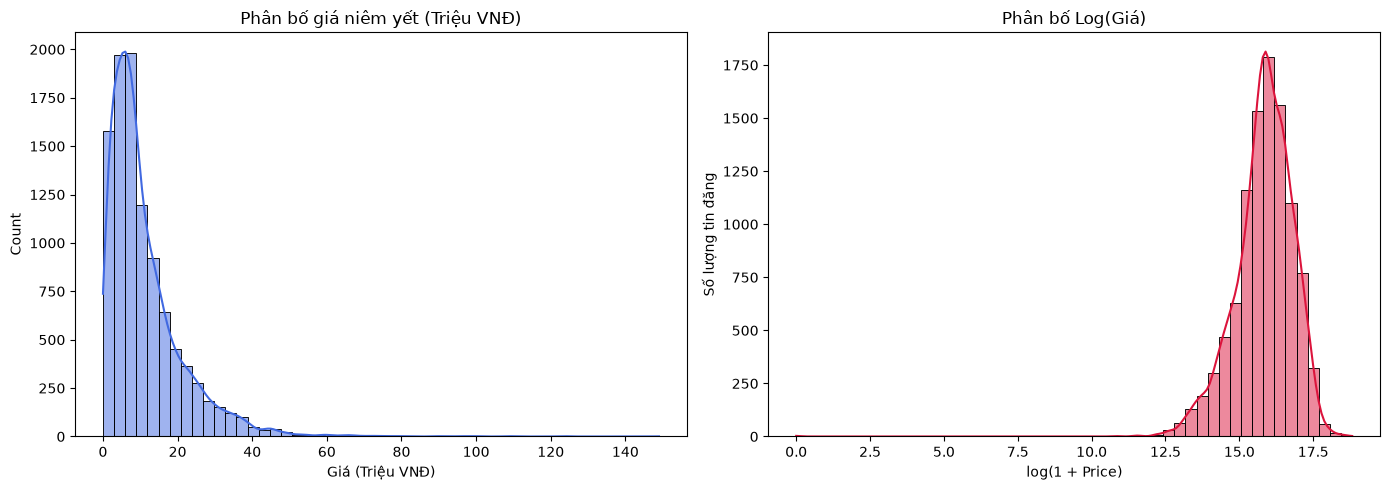

In [10]:
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
sns.histplot(df['target_price'].dropna() / 1e6, bins=50, kde=True, color='royalblue')
plt.title("Phân bố giá niêm yết (Triệu VNĐ)")
plt.xlabel("Giá (Triệu VNĐ)")

plt.subplot(1, 2, 2)
sns.histplot(np.log1p(df['target_price'].dropna()), bins=50, kde=True, color='crimson')
plt.title("Phân bố Log(Giá)")
plt.xlabel("log(1 + Price)")
plt.ylabel("Số lượng tin đăng")
plt.ylabel("Số lượng tin đăng")

plt.tight_layout()
plt.show()

In [11]:
price_desc = (df['target_price'] / 1e6).describe()
print("Thống kê mô tả giá (Triệu VNĐ):")
price_desc

Thống kê mô tả giá (Triệu VNĐ):


count    10143.000000
mean        11.165326
std         10.213197
min          0.000000
25%          4.500000
50%          8.100000
75%         14.800000
max        149.000000
Name: target_price, dtype: float64

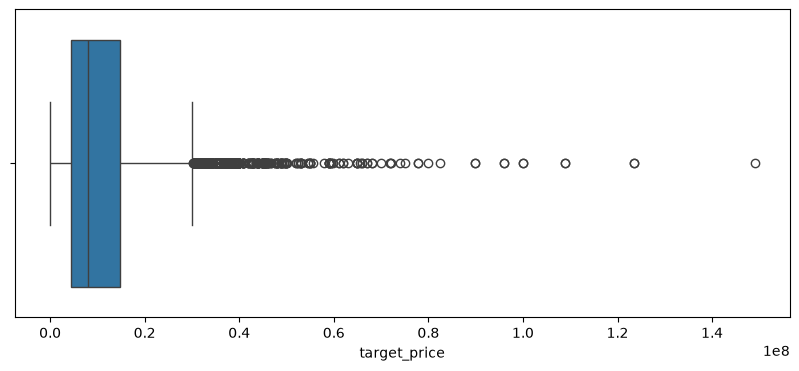

In [12]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=df['target_price'])
#plt.title("Boxplot của Target Price")
plt.show()

---
# UNIVARIATE ANALYSIS
---

## Brand (thương hiệu)

In [13]:
df['brand_name'].unique()

<StringArray>
[       'hp',      'dell',      'asus',    'lenovo',     'apple',      'acer',
       'msi',         nan,   'toshiba', 'microsoft',   'samsung',   'fujitsu',
    'xiaomi',        'lg',    'huawei']
Length: 15, dtype: str

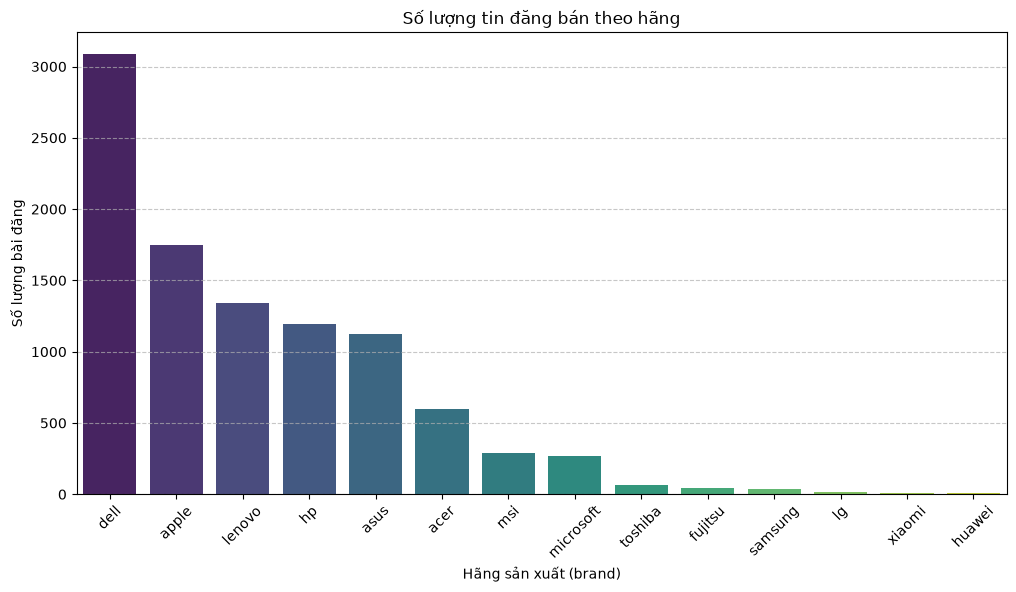

In [14]:
plt.figure(figsize=(12, 6))
sns.countplot(
    data=df, 
    x='brand_name', 
    order=df['brand_name'].value_counts().index, 
    palette='viridis' # Bảng màu gradient
)
plt.title("Số lượng tin đăng bán theo hãng")
plt.xlabel("Hãng sản xuất (brand)")
plt.ylabel("Số lượng bài đăng")
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [15]:
null_brand = df['brand_name'].isnull().sum()
print(f"Số lượng tin đăng không trích xuất được hãng máy: {null_brand}, chiếm {(null_brand/df.shape[0])*100:.2f}% tổng số bài đăng")

Số lượng tin đăng không trích xuất được hãng máy: 308, chiếm 3.04% tổng số bài đăng


## Product line (Dòng máy)

In [16]:
df['product_line'].unique()

<StringArray>
['elitebook 840 g3',   'latitude e5470',    'latitude 5400',
      'vostro 3400',   'precision 7530',              'xps',
    'latitude 5500',   'probook 440 g7',    'latitude 5410',
    'latitude 5501',
 ...
      'ideapad 310',    'inspiron 7447',           'xps 16',
  'probook 460 g11',    'latitude 5570',    'latitude 7640',
      'vostro 5490',    'latitude 3380',    'inspiron 7300',
    'latitude 3350']
Length: 624, dtype: str

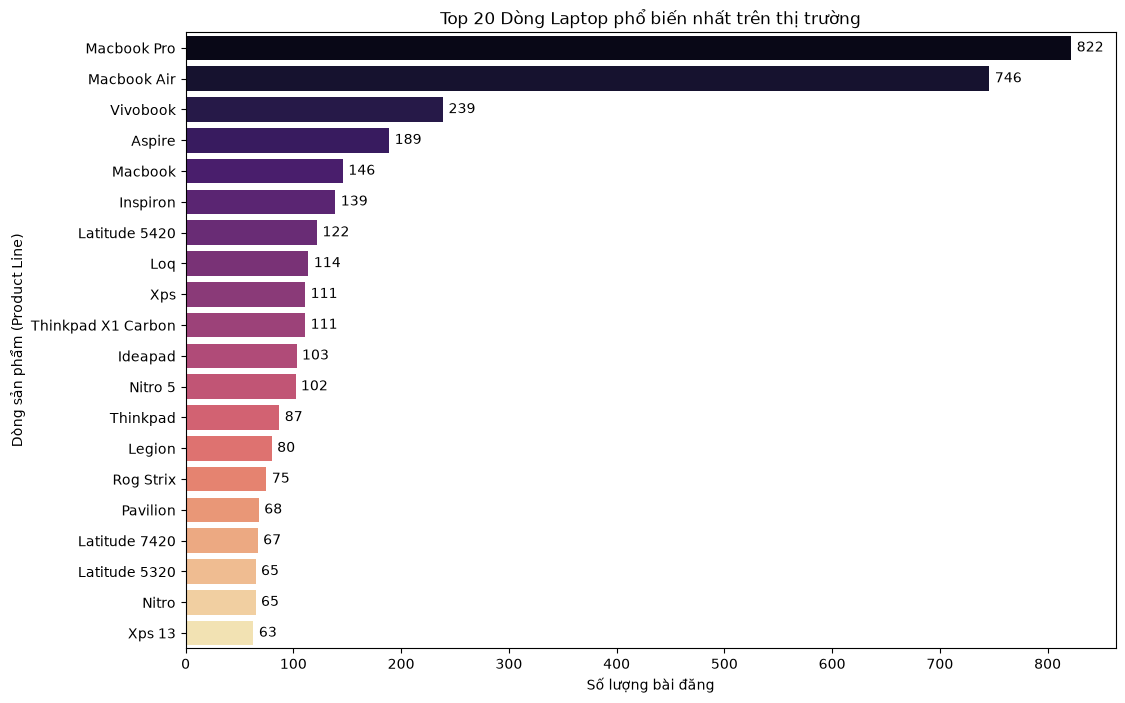

In [17]:
plt.figure(figsize=(12, 8))
valid_lines = df['product_line'].dropna().astype(str).str.strip().str.title()
top_20_lines = valid_lines.value_counts().head(20)
sns.barplot(x=top_20_lines.values, y=top_20_lines.index, palette='magma')
plt.title('Top 20 Dòng Laptop phổ biến nhất trên thị trường')
plt.xlabel('Số lượng bài đăng')
plt.ylabel('Dòng sản phẩm (Product Line)')

for i, v in enumerate(top_20_lines.values):
    plt.text(v + 5, i, str(v), color='black', va='center')

plt.show()

In [18]:
missing_lines = df['product_line'].isna().sum()
print(f"Số bài đăng không rõ dòng máy (Null): {missing_lines} ({missing_lines/len(df)*100:.1f}%)")
print(f"Tổng số dòng máy (Unique) phát hiện được: {df['product_line'].nunique()}")

Số bài đăng không rõ dòng máy (Null): 2236 (22.0%)
Tổng số dòng máy (Unique) phát hiện được: 623


## CPU Vendor

In [20]:
df['cpu_vendor'].unique()

<StringArray>
[nan, 'intel', 'amd', 'apple']
Length: 4, dtype: str

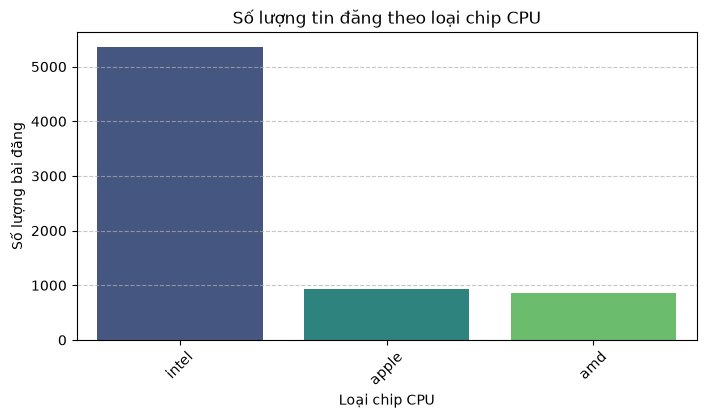

In [21]:
plt.figure(figsize=(8, 4))
sns.countplot(
    data=df,
    x="cpu_vendor",
    order=df['cpu_vendor'].value_counts().index,
    palette="viridis"
)
plt.xlabel("Loại chip CPU")
plt.ylabel("Số lượng bài đăng")
plt.title("Số lượng tin đăng theo loại chip CPU")
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [22]:
null_cpu_vendor = df['cpu_vendor'].isnull().sum()
print(f"Số lượng bài đăng không thu thập được loại chip CPU: {null_cpu_vendor}, chiếm {(null_cpu_vendor/df.shape[0])*100:.2f}% tổng số bài đăng")

Số lượng bài đăng không thu thập được loại chip CPU: 2986, chiếm 29.44% tổng số bài đăng


## CPU Model

### Dòng Intel

In [23]:
print(df[df['cpu_vendor'] == 'intel']['cpu_model'].unique())

<StringArray>
[   'i5 6440hq',     'i7 8665u',    'i7-1165g7',     'i7 8850h',
     'i7-8665u',    'i5 10310u',    'i5-10310u',     'i7-9850h',
    'i7 10510u',    'i7 10610u',
 ...
       'i5-125',    'i5-12600h',     'i3 8145u',      'i7-2160',
     'i9-9880h',     'i7-770hq',    'i7 4720hq', 'ultra 7 255u',
     'i7-1075h',      'i3 2330']
Length: 482, dtype: str


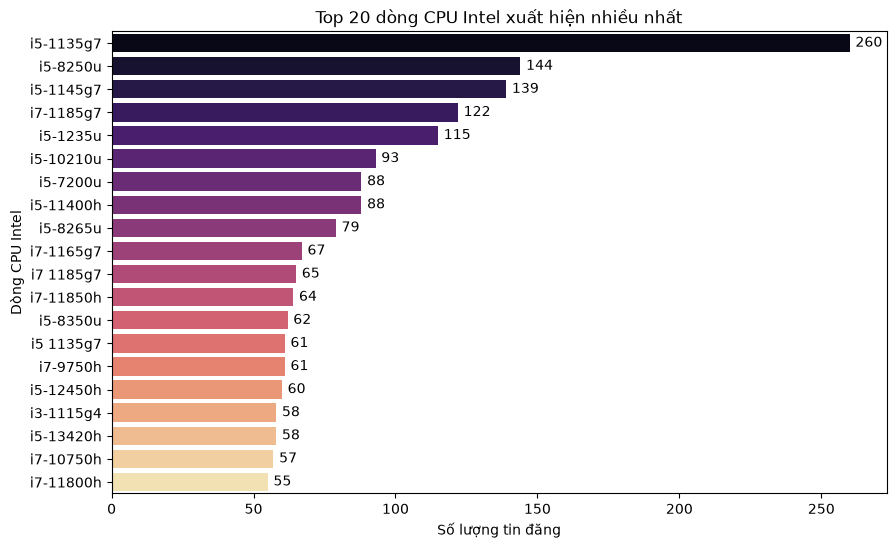

In [24]:
intel_chips = df[df['cpu_vendor'] == 'intel']['cpu_model'].value_counts()
intel_chips_top20 = intel_chips.head(20)

plt.figure(figsize=(10, 6))
sns.barplot(x=intel_chips_top20.values, y=intel_chips_top20.index, palette='magma')
plt.title("Top 20 dòng CPU Intel xuất hiện nhiều nhất")
plt.xlabel("Số lượng tin đăng")
plt.ylabel("Dòng CPU Intel")

for i, v in enumerate(intel_chips_top20.values):
    plt.text(v + 2, i, str(v), color='black', va='center')

plt.show()

In [25]:
rare_intel_cpus = intel_chips[intel_chips < 5]
rare_pct = (len(rare_intel_cpus) / len(intel_chips)) * 100

print(f"Tổng số mã CPU Intel xuất hiện: {len(intel_chips)}")
print(f"Số lượng mã CPU Intel < 5 lần (hiếm): {len(rare_intel_cpus)}, chiếm {rare_pct:.2f}% toàn bộ mã Intel")

rare_listing_intel_pct = (rare_intel_cpus.sum() / intel_chips.sum()) * 100
print(f"Tỷ trọng bài đăng chứa CPU Intel hiếm: {rare_listing_intel_pct:.2f}%")

Tổng số mã CPU Intel xuất hiện: 482
Số lượng mã CPU Intel < 5 lần (hiếm): 271, chiếm 56.22% toàn bộ mã Intel
Tỷ trọng bài đăng chứa CPU Intel hiếm: 10.66%


In [26]:
noise_intel = intel_chips[intel_chips == 1].index.to_list()
print("Danh sách 20 mã CPU Intel cực hiếm:")
noise_intel[:20]

Danh sách 20 mã CPU Intel cực hiếm:


['i3-1005g7',
 'ultra 7-255h',
 'ultra 9 386h',
 'core ultra 7-165h',
 'i7 4700',
 'i7 4500u',
 'i9-12950hx',
 'i5-5250u',
 'i3 1035g4',
 'i3 5437',
 'core ultra 7-155u',
 'i3 7100u',
 'i5-10130u',
 'i7 1360p',
 'i5 320',
 'i7 1051',
 'i3-1115',
 'core ultra 7-165u',
 'i7 10210u',
 'i7 6780hq']

### Dòng AMD

In [27]:
print(df[df['cpu_vendor'] == 'amd']['cpu_model'].unique())

<StringArray>
[  'ryzen5 pro 4650u',            'ryzen 7',     'ryzen 9 8940hx',
      'ryzen 7 4800h',     'ryzen 9 8945hx',      'ryzen 7 5800h',
      'ryzen 5 8540u',     'ryzen 5 7535hs',      'ryzen 5 5500u',
            'ryzen 5',      'ryzen 7 3700u',      'ryzen 5 7430u',
      'ryzen 7 5700u',      'ryzen 7 6800h',     'ryzen 9 7945hx',
      'ryzen 7 3750h',      'ryzen 5 4300u',      'ryzen 5 5600h',
      'ryzen 7 7730u',      'ryzen 5 4500u',     'ryzen 7 7535hs',
     'ryzen 7 8845hs',      'ryzen 5 6600h',     'ryzen 7 7840hs',
      'ryzen 5 3550h',             'ryzen5',            'ryzen 3',
      'ryzen 5 4600h',     'ryzen 7 7435hs',      'ryzen 3 7320u',
      'ryzen 5 7520u',            'ryzen 9',      'ryzen 3 3250u',
      'ryzen 3 3200u',      'ryzen 7 5800u',      'ryzen 5 7530u',
     'ryzen 7 5800hs', 'ryzen 9 pro 7940hs',     'ryzen 7 7735hs',
  'ryzen 5 pro 2500u',     'ryzen 7 6800hs',      'ryzen 5 3500u',
     'ryzen 5 7640hs',  'ryzen 5 pro 7530u',    

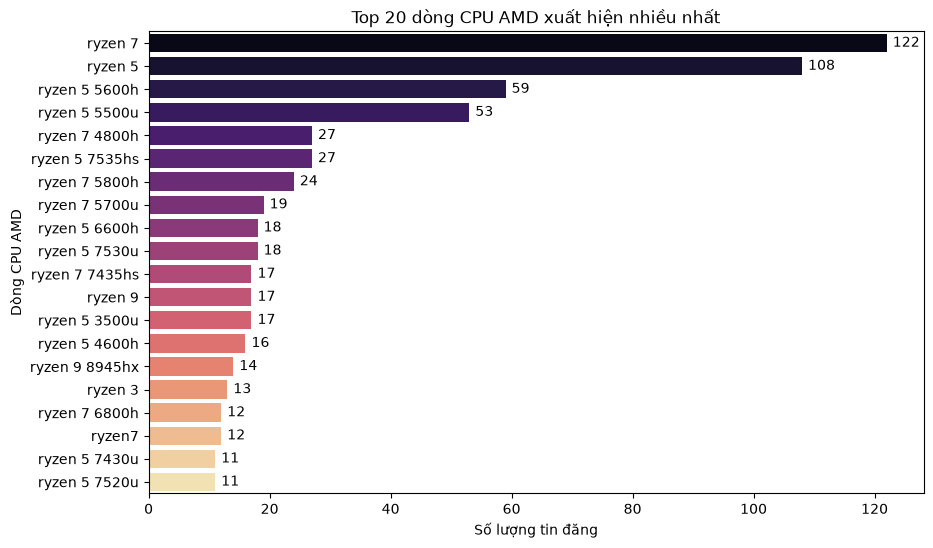

In [28]:
amd_chips = df[df['cpu_vendor'] == 'amd']['cpu_model'].value_counts()
amd_chips_top20 = amd_chips.head(20)

plt.figure(figsize=(10, 6))
sns.barplot(x=amd_chips_top20.values, y=amd_chips_top20.index, palette='magma')
plt.title("Top 20 dòng CPU AMD xuất hiện nhiều nhất")
plt.xlabel("Số lượng tin đăng")
plt.ylabel("Dòng CPU AMD")

for i, v in enumerate(amd_chips_top20.values):
    plt.text(v + 1, i, str(v), color='black', va='center')

plt.show()

In [29]:
rare_amd_cpus = amd_chips[amd_chips < 5]
rare_pct = (len(rare_amd_cpus) / len(amd_chips)) * 100

print(f"Tổng số mã CPU AMD xuất hiện: {len(amd_chips)}")
print(f"Số lượng mã CPU AMD < 5 lần (hiếm): {len(rare_amd_cpus)}, chiếm {rare_pct:.2f}% toàn bộ mã amd")

rare_listing_amd_pct = (rare_amd_cpus.sum() / amd_chips.sum()) * 100
print(f"Tỷ trọng bài đăng chứa CPU AMD hiếm: {rare_listing_amd_pct:.2f}%")

Tổng số mã CPU AMD xuất hiện: 91
Số lượng mã CPU AMD < 5 lần (hiếm): 56, chiếm 61.54% toàn bộ mã amd
Tỷ trọng bài đăng chứa CPU AMD hiếm: 13.65%


In [30]:
noise_amd = amd_chips[amd_chips == 1].index.to_list()
print("Danh sách 20 mã CPU AMD cực hiếm:")
noise_amd[:20]

Danh sách 20 mã CPU AMD cực hiếm:


['ryzen 5 pro 7530u',
 'ryzen5 6600h',
 'ryzen 3 3200',
 'ryzen 7 7445hs',
 'ryzen 5 6600hs',
 'ryzen 7 5825u',
 'ryzen 5 4800h',
 'ryzen7 4800h',
 'ryzen7 3750h',
 'ryzen 7 5850u',
 'ryzen 5 5800h',
 'ryzen7 5800h',
 'ryzen 7 8745hs',
 'ryzen 7 pro',
 'ryzen 9 4900h',
 'ryzen7 pro 5850u',
 'ryzen 9 5900hx']

### Dòng Apple

In [31]:
print(df[df['cpu_vendor'] == 'apple']['cpu_model'].unique())

<StringArray>
[    'm1',     'm4',     'm2', 'm3 pro',     'm3', 'm1 pro', 'm2 pro',
 'm2 max', 'm1 max', 'm4 pro', 'm3 max', 'm4 max']
Length: 12, dtype: str


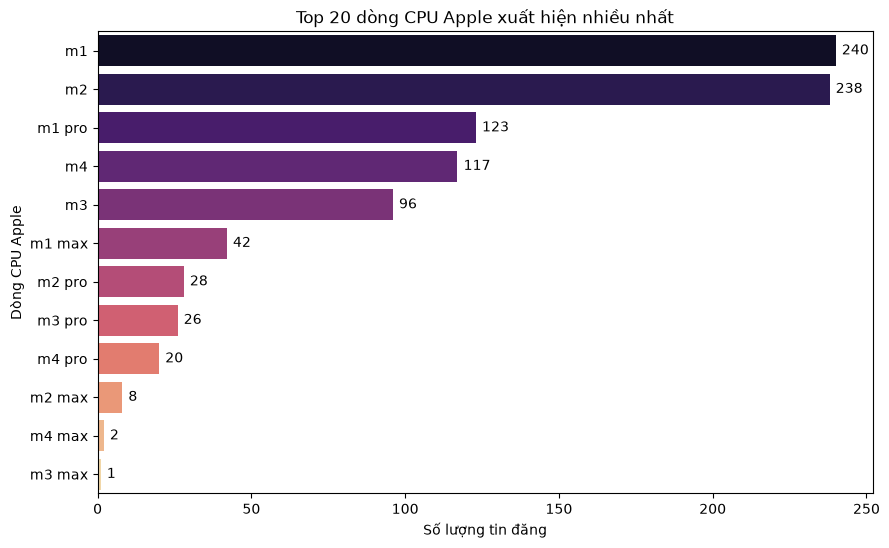

In [32]:
apple_chips = df[df['cpu_vendor'] == 'apple']['cpu_model'].value_counts()
apple_chips_top20 = apple_chips.head(20)

plt.figure(figsize=(10, 6))
sns.barplot(x=apple_chips_top20.values, y=apple_chips_top20.index, palette='magma')
plt.title("Top 20 dòng CPU Apple xuất hiện nhiều nhất")
plt.xlabel("Số lượng tin đăng")
plt.ylabel("Dòng CPU Apple")

for i, v in enumerate(apple_chips_top20.values):
    plt.text(v + 2, i, str(v), color='black', va='center')

plt.show()

In [33]:
rare_apple_cpus = apple_chips[apple_chips < 5]
rare_pct = (len(rare_apple_cpus) / len(apple_chips)) * 100

print(f"Tổng số mã CPU Apple xuất hiện: {len(apple_chips)}")
print(f"Số lượng mã CPU Apple < 5 lần (hiếm): {len(rare_apple_cpus)}, chiếm {rare_pct:.2f}% toàn bộ mã Apple")

rare_listing_apple_pct = (rare_apple_cpus.sum() / apple_chips.sum()) * 100
print(f"Tỷ trọng bài đăng chứa CPU Apple hiếm: {rare_listing_apple_pct:.2f}%")

Tổng số mã CPU Apple xuất hiện: 12
Số lượng mã CPU Apple < 5 lần (hiếm): 2, chiếm 16.67% toàn bộ mã Apple
Tỷ trọng bài đăng chứa CPU Apple hiếm: 0.32%


In [34]:
noise_apple = apple_chips[apple_chips == 1].index.to_list()
print("Danh sách 20 mã CPU Apple cực hiếm:")
noise_apple[:20]

Danh sách 20 mã CPU Apple cực hiếm:


['m3 max']

## RAM (Random Access Memory)

In [35]:
df['raw_ram'].unique()

<StringArray>
[  '8 GB',  '16 GB',   '4 GB',      nan,  '32 GB',   'Khác',   '6 GB',
  '64 GB',  '24 GB',   '2 GB',  '18 GB',  '12 GB',  '20 GB',  '48 GB',
  '10 GB',  '<1 GB', '128 GB',   '7 GB',   '3 GB',  '36 GB']
Length: 20, dtype: str

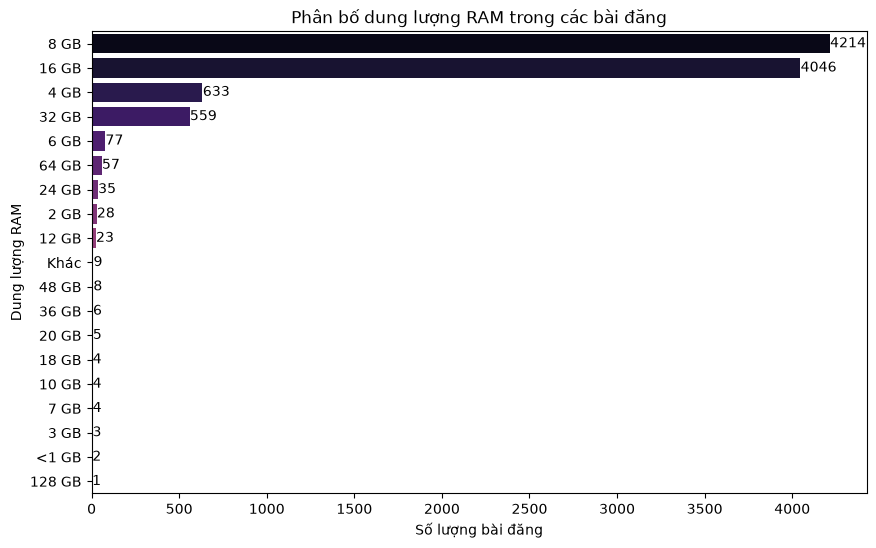

In [36]:
ram_counts = df['raw_ram'].value_counts()

plt.figure(figsize=(10, 6))
sns.barplot(x=ram_counts.values, y=ram_counts.index, palette='magma')
plt.title("Phân bố dung lượng RAM trong các bài đăng")
plt.xlabel("Số lượng bài đăng")
plt.ylabel("Dung lượng RAM")

for i, v in enumerate(ram_counts):
    plt.text(v + 2, i, str(v), color='black', va='center')
    
plt.show()

In [37]:
print(f"Số lượng bài đăng khuyết dữ liệu RAM: {df['raw_ram'].isnull().sum()}, chiếm {(df['raw_ram'].isnull().sum() / df.shape[0])*100:.2f}% tổng số bài đăng")

Số lượng bài đăng khuyết dữ liệu RAM: 425, chiếm 4.19% tổng số bài đăng


In [38]:
df[df['raw_ram'] == '2 GB']

,post_id,target_price,raw_cpu,raw_ram,raw_hard_drive,raw_hard_drive_type,pc_brand,pc_cpu,pc_ram,laptop_screen_size,...,battery_condition,warranty_months,warranty_type,has_warranty,is_upgraded,repair_status,year_production,year_purchase,bundles,has_bundle
515,135445065,500000.0,Intel Pentium,2 GB,500 GB,HDD,5,9.0,3.0,4.0,...,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,0
870,135561491,800000.0,Intel Celeron,2 GB,500 GB,HDD,7,3.0,3.0,NaN,...,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,0
2252,135456520,500000.0,Intel Pentium,2 GB,NaN,NaN,11,9.0,3.0,NaN,...,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,0
2291,135462065,800000.0,Intel Atom,2 GB,< 128 GB,SSD,12,2.0,3.0,2.0,...,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,sạc,1
2522,135566611,800000.0,Intel Celeron,2 GB,< 128 GB,SSD,6,3.0,3.0,3.0,...,NaN,NaN,NaN,0,NaN,original,2015.0,NaN,NaN,0
3077,135705018,1200000.0,NaN,2 GB,< 128 GB,SSD,3,NaN,3.0,NaN,...,worn,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,0
3079,135705122,700000.0,Khác,2 GB,NaN,NaN,10,10.0,3.0,NaN,...,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,0
3108,135711545,800000.0,Intel Core i3,2 GB,250 GB,HDD,5,6.0,3.0,NaN,...,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,0
3198,135725603,500000.0,Khác,2 GB,256 GB,HDD,6,10.0,3.0,NaN,...,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,0
4026,135555220,2000000.0,Intel Core i3,2 GB,NaN,HDD,6,6.0,3.0,NaN,...,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,0


In [37]:
df[df['raw_ram'] == "<1 GB"]

,post_id,target_price,raw_cpu,raw_ram,raw_hard_drive,raw_hard_drive_type,pc_brand,pc_cpu,pc_ram,laptop_screen_size,...,battery_condition,warranty_months,warranty_type,has_warranty,is_upgraded,repair_status,year_production,year_purchase,bundles,has_bundle
2845,135465228,200000.0,Khác,<1 GB,< 128 GB,HDD,5,10.0,1.0,5.0,...,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,0


## Hard Drive (Ổ cứng)

### Type of Hard Drive (Phân loại ổ cứng)

In [39]:
df['raw_hard_drive_type'].unique()

<StringArray>
['SSD', nan, 'HDD']
Length: 3, dtype: str

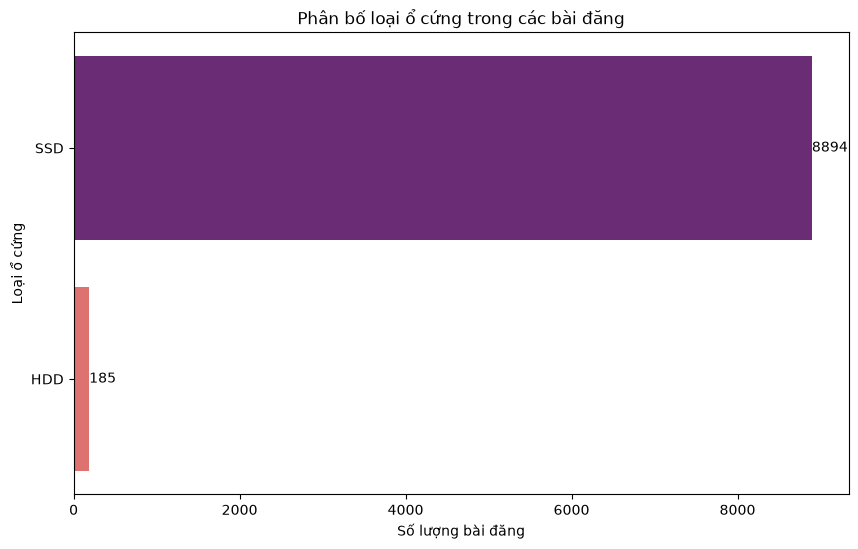

In [40]:
hard_drive_type = df['raw_hard_drive_type'].value_counts()

plt.figure(figsize=(10, 6))
sns.barplot(x=hard_drive_type.values, y=hard_drive_type.index, palette='magma')
plt.title("Phân bố loại ổ cứng trong các bài đăng")
plt.xlabel("Số lượng bài đăng")
plt.ylabel("Loại ổ cứng")

for i, v in enumerate(hard_drive_type):
    plt.text(v + 2, i, str(v), color='black', va='center')
    
plt.show()

In [41]:
print(f"Số lượng bài đăng khuyết dữ liệu phân loại ổ cứng: {df['raw_hard_drive_type'].isnull().sum()}, chiếm {(df['raw_hard_drive_type'].isnull().sum() / df.shape[0])*100:.2f}%")

Số lượng bài đăng khuyết dữ liệu phân loại ổ cứng: 1064, chiếm 10.49%


### Dung lượng ổ cứng

In [42]:
df['raw_hard_drive'].unique()

<StringArray>
[  '256 GB',   '512 GB',   '128 GB',     '1 TB',        nan, '< 128 GB',
     'Khác',   '480 GB',   '500 GB',   '250 GB',   '640 GB',   '320 GB',
     '2 TB',   '750 GB',     '3 TB',       '13']
Length: 16, dtype: str

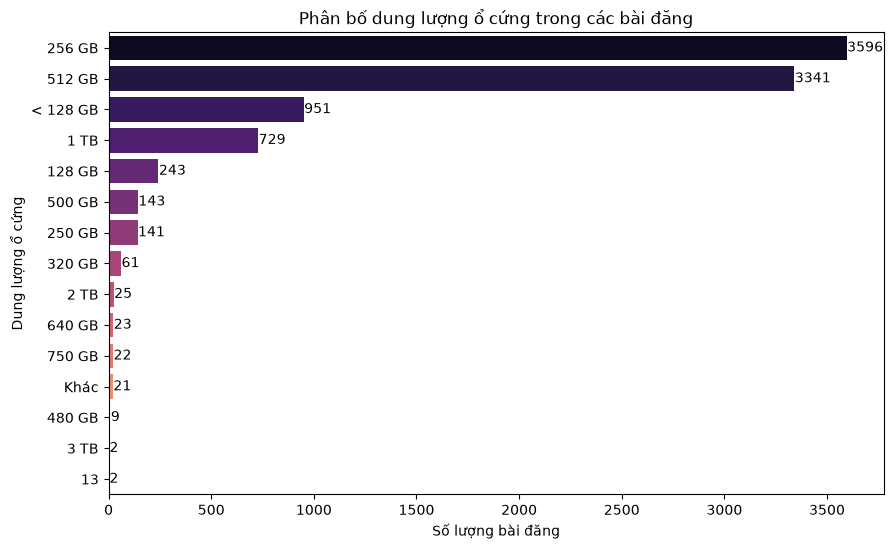

In [43]:
storage_hd = df['raw_hard_drive'].value_counts()

plt.figure(figsize=(10, 6))
sns.barplot(x=storage_hd.values, y=storage_hd.index, palette='magma')
plt.title("Phân bố dung lượng ổ cứng trong các bài đăng")
plt.xlabel("Số lượng bài đăng")
plt.ylabel("Dung lượng ổ cứng")

for i, v in enumerate(storage_hd):
    plt.text(v + 2, i, str(v), color='black', va='center')
    
plt.show()

In [44]:
print(f"Số lượng bài đăng khuyết dữ liệu dung lượng ổ cứng: {df['raw_hard_drive'].isnull().sum()}, chiếm {(df['raw_hard_drive'].isnull().sum() / df.shape[0])*100:.2f}%")

Số lượng bài đăng khuyết dữ liệu dung lượng ổ cứng: 834, chiếm 8.22%


## GPU (Graphic Process Unit)

### GPU Type (Loại GPU)

In [45]:
df['gpu_type'].unique()

<StringArray>
['integrated', 'discrete', nan]
Length: 3, dtype: str

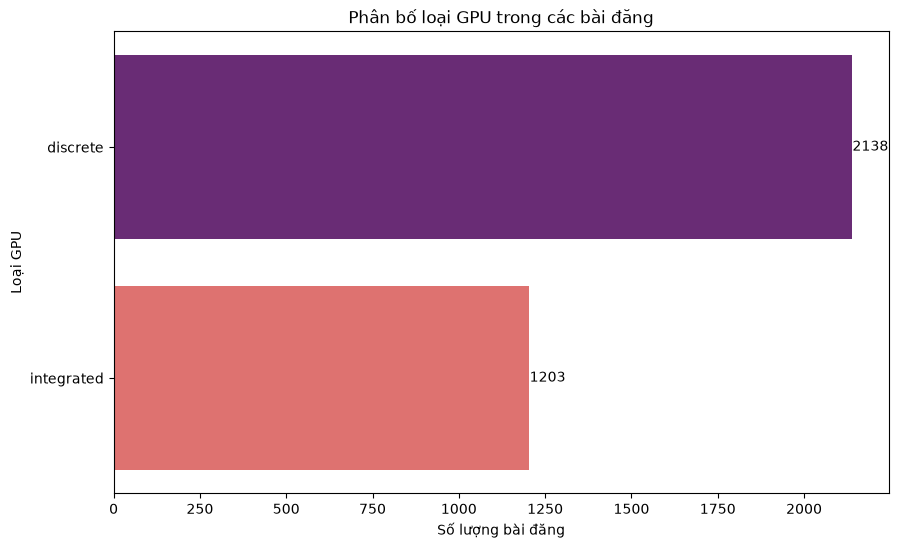

In [46]:
gpu_type = df['gpu_type'].value_counts()
plt.figure(figsize=(10, 6))
sns.barplot(x=gpu_type.values, y=gpu_type.index, palette='magma')
plt.title("Phân bố loại GPU trong các bài đăng")
plt.xlabel("Số lượng bài đăng")
plt.ylabel("Loại GPU")

for i, v in enumerate(gpu_type):
    plt.text(v + 2, i, str(v), color='black', va='center')
    
plt.show()


In [47]:
print(f"Số lượng bài đăng khuyết dữ liệu loại GPU: {df['gpu_type'].isnull().sum()}, chiếm {(df['gpu_type'].isnull().sum() / df.shape[0])*100:.2f}% tổng số bài đăng")

Số lượng bài đăng khuyết dữ liệu loại GPU: 6802, chiếm 67.06% tổng số bài đăng


### GPU Model

In [48]:
df['gpu_model'].unique()

<StringArray>
[       'intel hd',             'uhd',          'mx 330',    'quadro p1000',
               nan,          'mx 150',    'uhd graphics',    'quadro t1000',
         'iris xe',    'quadro t1200',
 ...
   'intel hd 4600',     'radeon 660m',        'rtx 4080',        'rtx 5090',
       'rtx a4500',        'rtx 3500',          'mx 920',     'radeon 860m',
     'quadro t550', 'radeon rx 5500m']
Length: 166, dtype: str

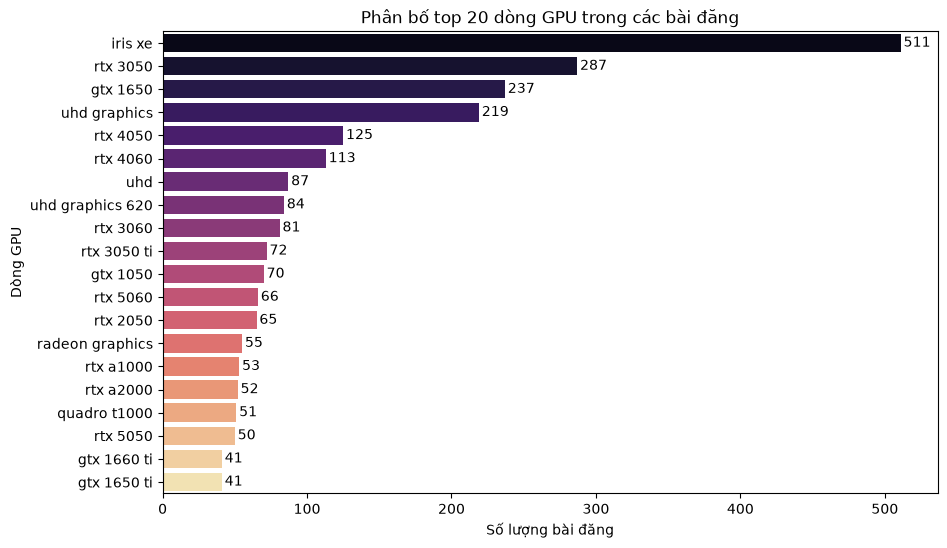

In [49]:
gpu_model = df['gpu_model'].value_counts()
gpu_model_top20 = gpu_model.head(20)

plt.figure(figsize=(10, 6))
sns.barplot(x=gpu_model_top20.values, y=gpu_model_top20.index, palette='magma')
plt.title("Phân bố top 20 dòng GPU trong các bài đăng")
plt.xlabel("Số lượng bài đăng")
plt.ylabel("Dòng GPU")

for i, v in enumerate(gpu_model_top20):
    plt.text(v + 2, i, str(v), color='black', va='center')
    
plt.show()

In [50]:
rare_gpu_model = gpu_model[gpu_model < 5]
rare_gpu_pct = (len(rare_gpu_model) / len(gpu_model)) * 100

print(f"Tổng số mã CPU duy nhất: {len(gpu_model)}")
print(f"Số lượng mã CPU xuất hiện < 5 lần (Mã hiếm): {len(rare_gpu_model)} ({rare_gpu_pct:.1f}% tổng số mã)")

Tổng số mã CPU duy nhất: 165
Số lượng mã CPU xuất hiện < 5 lần (Mã hiếm): 90 (54.5% tổng số mã)


In [51]:
rare_listings_gpu_pct = (rare_gpu_model.sum() / len(df.dropna(subset=['gpu_model']))) * 100
print(f"Tỷ trọng bài đăng chứa GPU hiếm: {rare_listings_gpu_pct:.2f}%")

Tỷ trọng bài đăng chứa GPU hiếm: 5.81%


In [52]:
print(f"Số bài đăng khuyết dữ liệu dung lượng VRAM GPU: {df['gpu_model'].isnull().sum()}, chiếm {(df['gpu_model'].isnull().sum() / df.shape[0])*100:.2f}% tổng số bài đăng")

Số bài đăng khuyết dữ liệu dung lượng VRAM GPU: 6802, chiếm 67.06% tổng số bài đăng


## Screen (Màn hình)

### Screen size (Kích thước màn hình)

In [53]:
df['screen_size_inch'].unique()

array([14. , 15.6, 13.3,  nan, 11. , 13.4, 17.3, 15. , 12.5, 16. , 15.4,
       13. , 12.2, 11.6, 12. , 14.1, 10. , 14.5, 15.5, 10.5, 12.3, 13.5,
       13.6, 17. , 16.1, 15.1, 12.4, 15.3, 14.4, 10.1, 18. , 12.1, 16.2,
       14.2, 16.3], dtype=float32)

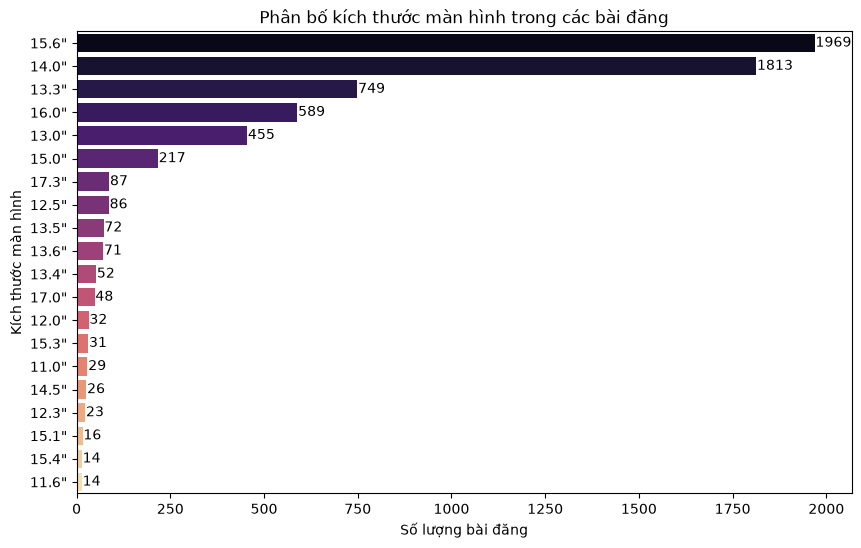

In [54]:
screen_size = df['screen_size_inch'].value_counts()
screen_size_top20 = screen_size.head(20)
clean_labels = screen_size_top20.index.to_series().round(1).astype(str) + '"'

plt.figure(figsize=(10, 6))
sns.barplot(x=screen_size_top20.values, y=clean_labels, palette='magma')
plt.title("Phân bố kích thước màn hình trong các bài đăng")
plt.xlabel("Số lượng bài đăng")
plt.ylabel("Kích thước màn hình")

for i, v in enumerate(screen_size_top20):
    plt.text(v + 2, i, str(v), color='black', va='center')
plt.show()

In [55]:
null_screen_size = df['screen_size_inch'].isnull().sum()
print(f"Số bài đăng khuyết kích thước màn hình: {null_screen_size}, chiếm {(null_screen_size / df.shape[0])*100:.2f}% tổng bài đăng")

Số bài đăng khuyết kích thước màn hình: 3662, chiếm 36.10% tổng bài đăng


### Resolution (Độ phân giải)

In [56]:
df['resolution'].unique()

<StringArray>
['fhd', 'retina', 'fhd+', nan, '4k/uhd', '3k', '2k/qhd', 'qhd+']
Length: 8, dtype: str

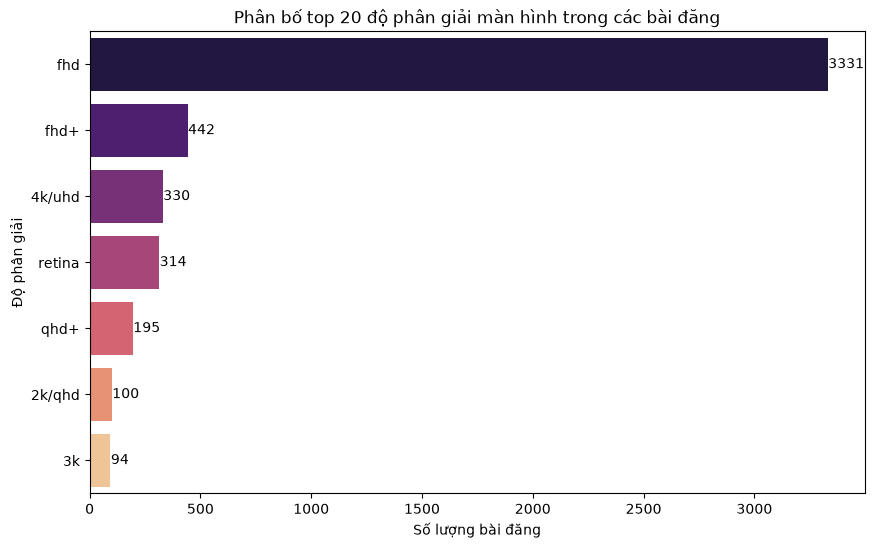

In [57]:
resolution = df['resolution'].value_counts()
resolution_top20 = resolution.head(20)

plt.figure(figsize=(10, 6))
sns.barplot(x=resolution_top20.values, y=resolution_top20.index, palette='magma')
plt.title("Phân bố top 20 độ phân giải màn hình trong các bài đăng")
plt.xlabel("Số lượng bài đăng")
plt.ylabel("Độ phân giải")

for i, v in enumerate(resolution_top20):
    plt.text(v + 2, i, str(v), color='black', va='center')
    
plt.show()

In [58]:
rare_resolution = resolution[resolution < 5]
rare_resolution_pct = (len(rare_resolution) / len(resolution)) * 100

print(f"Tổng số mã CPU duy nhất: {len(resolution)}")
print(f"Số lượng mã CPU xuất hiện < 5 lần (Mã hiếm): {len(rare_resolution)} ({rare_resolution_pct:.1f}% tổng số mã)")

Tổng số mã CPU duy nhất: 7
Số lượng mã CPU xuất hiện < 5 lần (Mã hiếm): 0 (0.0% tổng số mã)


In [59]:
rare_listings_resolution_pct = (rare_resolution.sum() / len(df.dropna(subset=['resolution']))) * 100
print(f"Tỷ trọng bài đăng chứa CPU hiếm: {rare_listings_resolution_pct:.2f}%")

Tỷ trọng bài đăng chứa CPU hiếm: 0.00%


In [60]:
null_resolution = df['resolution'].isnull().sum()
print(f"Tổng số bài đăng khuyết độ phân giải màn hình: {null_screen_size}, chiếm tỷ lệ {(null_resolution / df.shape[0])*100:.2f}% tổng số bài đăng")

Tổng số bài đăng khuyết độ phân giải màn hình: 3662, chiếm tỷ lệ 52.62% tổng số bài đăng


### Torch sensitive (Màn hình cảm ứng)

In [61]:
df['touch_sensitive'].unique()

array([nan,  1.,  0.])

In [62]:
df['touch_sensitive'] = df['touch_sensitive'].fillna(0).astype(int)
touch_sensitive = df['touch_sensitive'].value_counts()

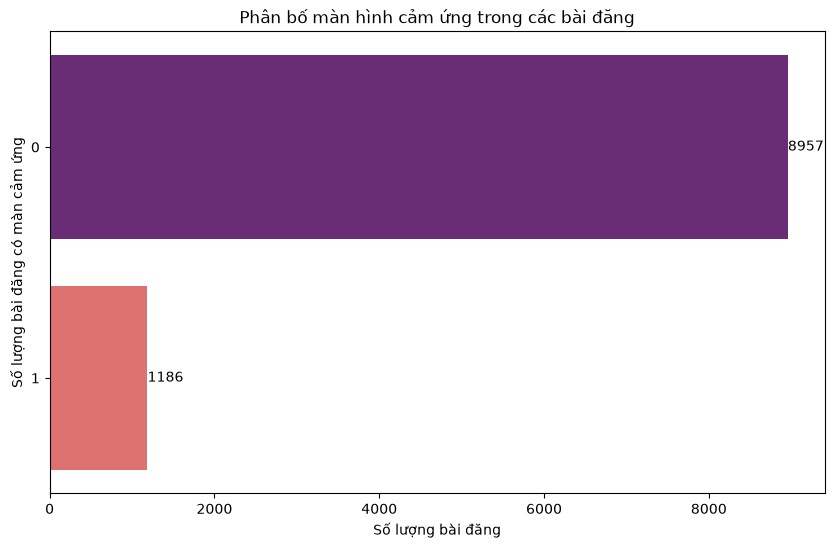

In [63]:
plt.figure(figsize=(10, 6))
sns.barplot(x=touch_sensitive.values, y=touch_sensitive.index.astype(str), palette='magma')
plt.title("Phân bố màn hình cảm ứng trong các bài đăng")
plt.xlabel("Số lượng bài đăng")
plt.ylabel("Số lượng bài đăng có màn cảm ứng")

for i, v in enumerate(touch_sensitive):
    plt.text(v + 2, i, str(v), color='black', va='center')
    
plt.show()

## Battery

### Battery Condition (Tình trạng pin dạng chữ được trích xuất)

In [64]:
df['battery_condition'].unique()

<StringArray>
[nan, 'good', 'replaced', 'worn']
Length: 4, dtype: str

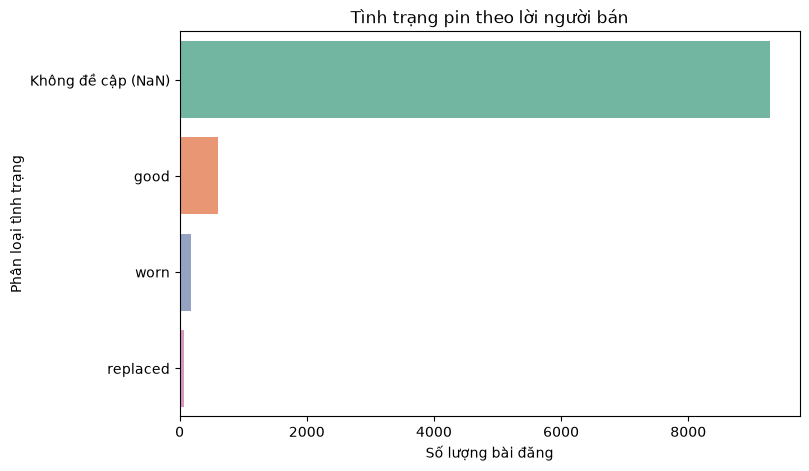

In [65]:
plt.figure(figsize=(8, 5))
cond_counts = df['battery_condition'].fillna('Không đề cập (NaN)').value_counts()
sns.barplot(x=cond_counts.values, y=cond_counts.index, palette='Set2')
plt.title('Tình trạng pin theo lời người bán')
plt.xlabel('Số lượng bài đăng')
plt.ylabel('Phân loại tình trạng')
plt.show()

In [66]:
null_battery_cond = df['battery_condition'].isnull().sum()
print(f"Số bài đăng khuyết thông tin tình trạng pin từ văn bản {null_battery_cond} ,chiếm {(null_battery_cond / df.shape[0])*100:.2f}% tổng số bài đăng" )

Số bài đăng khuyết thông tin tình trạng pin từ văn bản 9287 ,chiếm 91.56% tổng số bài đăng


### Battery cycles (Chu kỳ sạc)

In [67]:
df['battery_cycles'].unique()

array([ nan,  72., 189., 152.,  99., 216.,  40., 100., 193.,  81.,   5.,
       390.,  10., 104.,   3.,  19., 202.,  20.])

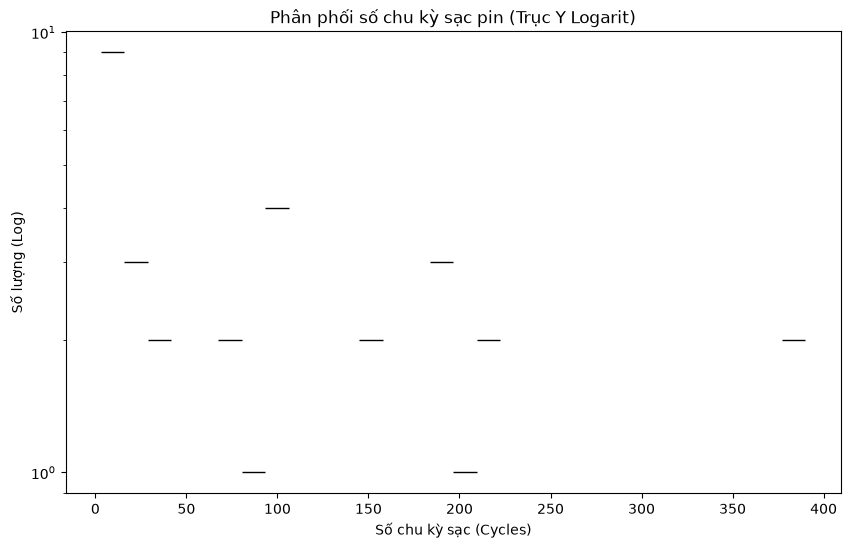

In [68]:
plt.figure(figsize=(10, 6))
valid_cycles = df['battery_cycles'].dropna()
sns.histplot(valid_cycles, bins=30, color='blue', log_scale=(False, True))
plt.title('Phân phối số chu kỳ sạc pin (Trục Y Logarit)')
plt.xlabel('Số chu kỳ sạc (Cycles)')
plt.ylabel('Số lượng (Log)')
plt.show()

In [69]:
null_battery_cycles = df['battery_cycles'].isnull().sum()
print(f"Số bài đăng khuyết dữ liệu chu kỳ sạc: {null_battery_cycles}, chiếm {(null_battery_cycles / df.shape[0])*100:.2f}% tổng số bài đăng")

Số bài đăng khuyết dữ liệu chu kỳ sạc: 10112, chiếm 99.69% tổng số bài đăng


### Battery hours (Tổng số giờ sạc)

In [70]:
df['battery_hours'].unique()

array([ 3. ,  4. ,  nan,  2. ,  5. ,  4.5,  6. ,  1.5,  3.5,  2.5,  1. ,
        2.3,  7. ,  8. , 16. , 10. ], dtype=float32)

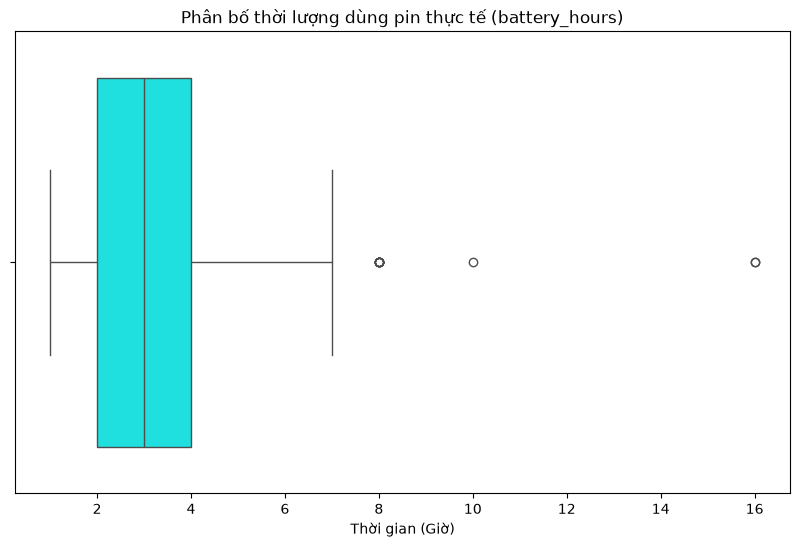

In [71]:
plt.figure(figsize=(10, 6))
valid_hours = df['battery_hours'].dropna()
sns.boxplot(x=valid_hours, color='cyan')
plt.title('Phân bố thời lượng dùng pin thực tế (battery_hours)')
plt.xlabel('Thời gian (Giờ)')
plt.show()

In [72]:
fake_battery = df[df['battery_hours'] > 15]
print(f"Số lượng máy có pin vô lý (> 15 tiếng): {len(fake_battery)}")

Số lượng máy có pin vô lý (> 15 tiếng): 2


In [73]:
null_battery_hours = df['battery_hours'].isnull().sum()
print(f"Số bài đăng khuyết thời gian sử dụng: {null_battery_cycles}, chiếm {(null_battery_cycles / df.shape[0])*100:.2f}% tổng bài đăng")

Số bài đăng khuyết thời gian sử dụng: 10112, chiếm 99.69% tổng bài đăng


### Battery percentage (% độ chai pin)

In [74]:
df['battery_pct'].unique()

array([ nan, 100.,  99.,  86.,  88.,  95.,  97.,  96.,  98.,  90.,  87.,
        78.,  89.,  77.,  84.,  85.,  92.,  75.,  60.,  91.,  82.,  83.,
        80.,  94.,  93.,  62.,  74.,  68.,  81.,  72.,  70.,  79.,  38.])

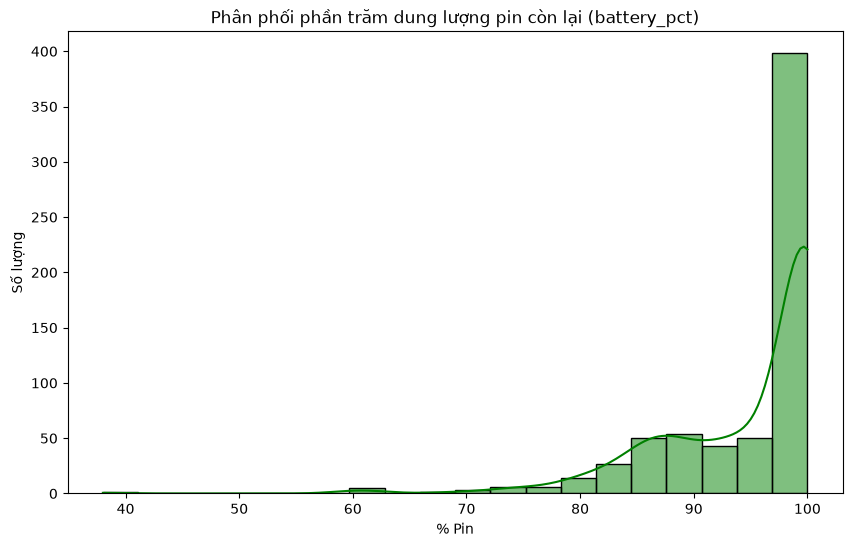

In [75]:
plt.figure(figsize=(10, 6))
valid_pct = df['battery_pct'].dropna()
sns.histplot(valid_pct, bins=20, kde=True, color='green')
plt.title('Phân phối phần trăm dung lượng pin còn lại (battery_pct)')
plt.xlabel('% Pin')
plt.ylabel('Số lượng')
plt.show()

In [76]:
pct_100 = (valid_pct == 100).sum()
print(f"Số bài đăng báo pin 100%: {pct_100} ({pct_100/len(valid_pct)*100:.2f}%)")

Số bài đăng báo pin 100%: 310 (47.11%)


In [77]:
null_battery_pct = df['battery_pct'].isnull().sum()
print(f"Số bài đăng khuyết dữ liệu về % pin: {null_battery_pct}, chiếm {(null_battery_pct / df.shape[0])*100:.2f}% tổng bài đăng")

Số bài đăng khuyết dữ liệu về % pin: 9485, chiếm 93.51% tổng bài đăng


## Condition (Độ mới ngoại hình máy trích xuất từ văn bản)

### New Seal (Máy mới 100% chưa kích hoạt)

In [78]:
df['is_new_seal'].unique()

array([nan,  1.])

In [79]:
new_seal = df['is_new_seal'].value_counts()
print(f"Số lượng bài đăng bán máy new seal: {new_seal.values}")

Số lượng bài đăng bán máy new seal: [118]


### Like new (Máy có ngoại hình 99%/Like new)

In [80]:
df['is_like_new'].unique()

array([ 1., nan])

In [81]:
like_new = df['is_like_new'].value_counts()
print(f"Số lượng bài đăng bán máy like new: {like_new.values}")

Số lượng bài đăng bán máy like new: [1168]


### Tỷ lệ độ mới trích xuất từ văn bản

In [82]:
df['condition_pct'].unique()

array([ nan,  99., 100.,  97.,  98.,  96.,  90.,  80.,  95.,  94.,  85.])

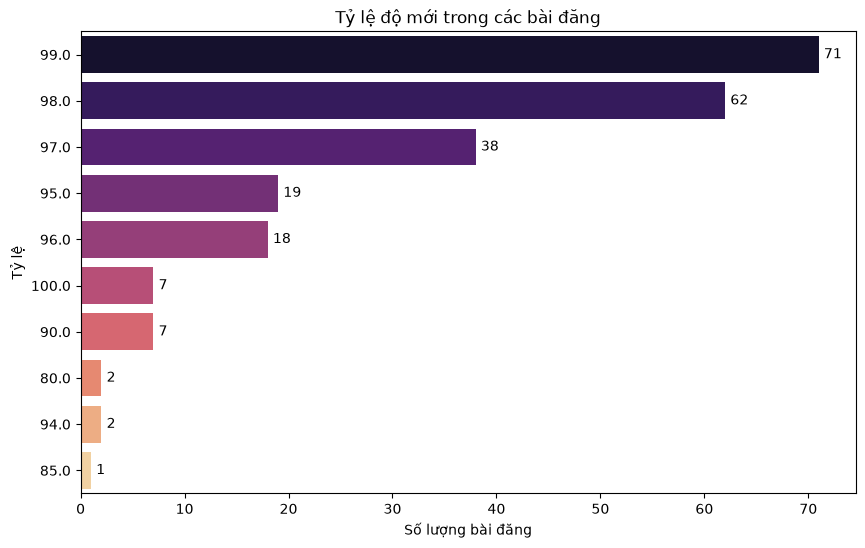

In [83]:
condition_pct = df['condition_pct'].value_counts()

plt.figure(figsize=(10, 6))
sns.barplot(x=condition_pct.values, y=condition_pct.index.astype(str), palette='magma')
plt.title("Tỷ lệ độ mới trong các bài đăng")
plt.xlabel("Số lượng bài đăng")
plt.ylabel("Tỷ lệ")

for i, v in enumerate(condition_pct):
    plt.text(v + 0.5, i, str(v), color='black', va='center')
    
plt.show()

In [84]:
null_condition_pct = df['condition_pct'].isnull().sum()
print(f"Các bài đăng khuyết tỷ lệ mới của máy: {null_condition_pct}, chiếm {(null_condition_pct / df.shape[0])*100:.2f}% tổng số bài đăng")

Các bài đăng khuyết tỷ lệ mới của máy: 9916, chiếm 97.76% tổng số bài đăng


### Repair status (Tình trạng sửa chữa của máy)

In [85]:
df['repair_status'].unique()

<StringArray>
['original', nan, 'repaired']
Length: 3, dtype: str

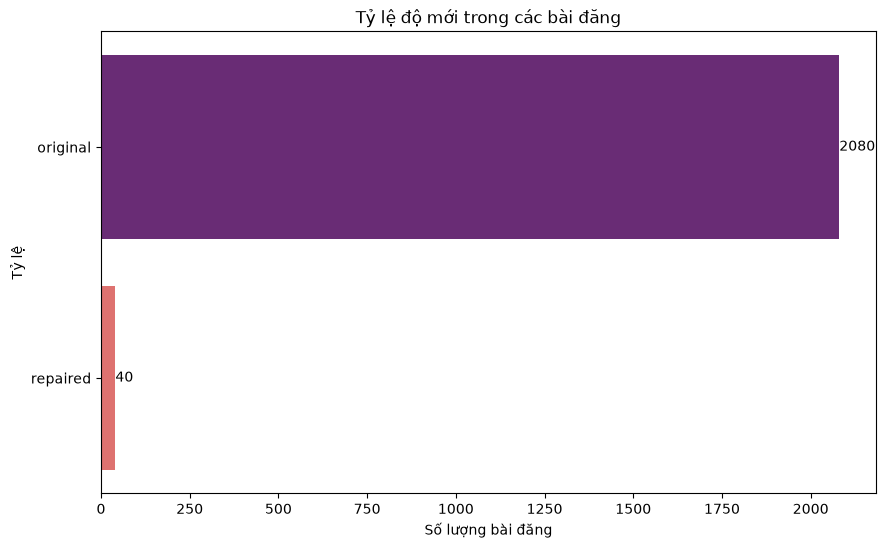

In [86]:
repair_status = df['repair_status'].value_counts()
plt.figure(figsize=(10, 6))
sns.barplot(x=repair_status.values, y=repair_status.index, palette='magma')
plt.title("Tỷ lệ độ mới trong các bài đăng")
plt.xlabel("Số lượng bài đăng")
plt.ylabel("Tỷ lệ")

for i, v in enumerate(repair_status):
    plt.text(v + 0.5, i, str(v), color='black', va='center')
    
plt.show()

In [87]:
null_repair_status = df["repair_status"].isnull().sum()
print(f"Số bài đăng khuyết tình trạng sửa chữa: {null_repair_status}, chiếm {(null_repair_status / df.shape[0])*100:.2f}% tổng bài đăng")

Số bài đăng khuyết tình trạng sửa chữa: 8023, chiếm 79.10% tổng bài đăng


## Seller rating & Region (Thông tin người bán và địa phương)

### Seller rating

In [88]:
df['seller_rating'].unique()

array([4.8, 4.7, 4.4, 4.9, 5. , 4.6, 3.9, nan, 4.5, 1. , 4.2, 3.4, 4.3,
       2. , 3. , 4.1, 3.7, 4. , 3.8, 3.5, 3.6, 2.3, 3.3, 2.9, 2.6, 3.1,
       2.5, 2.8, 2.2, 1.5], dtype=float32)

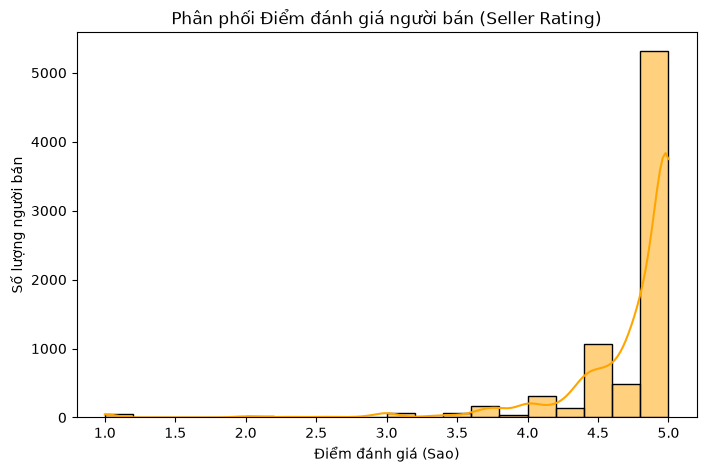

In [89]:
plt.figure(figsize=(8, 5))
valid_ratings = df[df['seller_rating'] > 0]['seller_rating']
sns.histplot(valid_ratings, bins=20, kde=True, color='orange')
plt.title('Phân phối Điểm đánh giá người bán (Seller Rating)')
plt.xlabel('Điểm đánh giá (Sao)')
plt.ylabel('Số lượng người bán')
plt.show()

In [90]:
bins = [-1, 5, 50, float('inf')]
labels = ['(0-5)', '(6-50)', '(>50)']
df['seller_type_eda'] = pd.cut(df['seller_sold_count'], bins=bins, labels=labels)
print("\nPhân loại người bán theo số lượng đã bán:")
print(df['seller_type_eda'].value_counts())


Phân loại người bán theo số lượng đã bán:
seller_type_eda
(>50)     4915
(6-50)    2798
(0-5)     2430
Name: count, dtype: int64


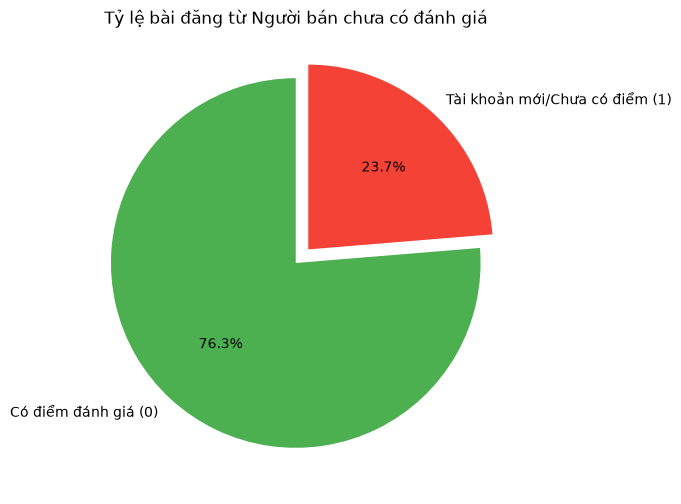

In [91]:
plt.figure(figsize=(6, 6))

missing_counts = df['is_seller_rating_missing'].value_counts()
labels = ['Có điểm đánh giá (0)', 'Tài khoản mới/Chưa có điểm (1)']

plt.pie(missing_counts, labels=labels, autopct='%1.1f%%', startangle=90, colors=['#4CAF50', '#F44336'], explode=(0, 0.1))
plt.title('Tỷ lệ bài đăng từ Người bán chưa có đánh giá')
plt.show()

### Region (Khu vực)

In [92]:
df['region_name'].unique()

<StringArray>
[     'TP Hà Nội',     'TP Cần Thơ', 'TP Hồ Chí Minh',       'An Giang',
      'Vĩnh Long',       'Bắc Ninh',       'Đồng Nai',     'TP Đà Nẵng',
       'Tây Ninh',        'Đắk Lắk',      'Đồng Tháp',   'TP Hải Phòng',
         'TP Huế',      'Khánh Hòa',       'Lâm Đồng',        'Lào Cai',
      'Quảng Trị',        'Phú Thọ',        'Gia Lai',        'Hà Tĩnh',
       'Hưng Yên',      'Ninh Bình',     'Quảng Ngãi',         'Cà Mau',
       'Lạng Sơn',         'Sơn La',    'Thái Nguyên',        'Nghệ An',
     'Quảng Ninh',    'Tuyên Quang',      'Thanh Hóa']
Length: 31, dtype: str

In [93]:
df['ward_name'].unique()

<StringArray>
[     'Phường Phú Diễn',        'Phường Tân An',       'Phường Đống Đa',
      'Phường Tân Hòa',     'Phường Việt Hưng',      'Phường Bình Tây',
     'Phường Diên Hồng',        'Phường Đại Mỗ',    'Phường Phước Long',
     'Phường Tân Bình',
 ...
        'Xã Phúc Thịnh',        'Phường Mỹ Hào', 'Phường Bắc Gia Nghĩa',
           'Xã Phú Tân',     'Phường Bình Minh',     'Xã Tân Hà Lâm Hà',
  'Phường Thiên Trường',           'Xã Phú Hòa',    'Phường Thượng Cát',
         'Xã Bát Tràng']
Length: 455, dtype: str

In [94]:
region_counts = df['region_name'].value_counts(dropna=False)
region_pct = (region_counts / df.shape[0]) * 100
print("Top 5 khu vực chiếm tỷ trọng lớn nhất:")
region_pct.head(5)

Top 5 khu vực chiếm tỷ trọng lớn nhất:


region_name
TP Hồ Chí Minh    56.511880
TP Hà Nội         19.491275
TP Đà Nẵng         7.423839
TP Cần Thơ         5.037957
Đồng Nai           1.577443
Name: count, dtype: float64

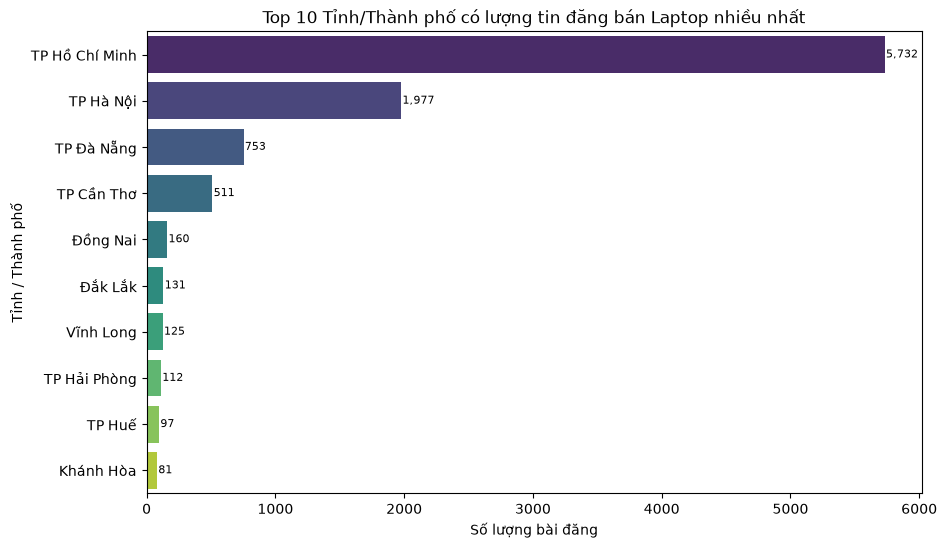

In [95]:
plt.figure(figsize=(10, 6))
sns.barplot(x=region_counts.head(10).values, y=region_counts.head(10).index.astype(str), palette='viridis', orient='h')
plt.title('Top 10 Tỉnh/Thành phố có lượng tin đăng bán Laptop nhiều nhất')
plt.xlabel('Số lượng bài đăng')
plt.ylabel('Tỉnh / Thành phố')

for i, v in enumerate(region_counts.head(10).values):
    plt.text(v + 10, i, f"{v:,.0f}", color='black', va='center', fontsize=8)

plt.show()

In [96]:
unique_wards = df['ward_name'].nunique()
print(f"Tổng số Phường/Xã duy nhất trong tập dữ liệu: {unique_wards}")

Tổng số Phường/Xã duy nhất trong tập dữ liệu: 455


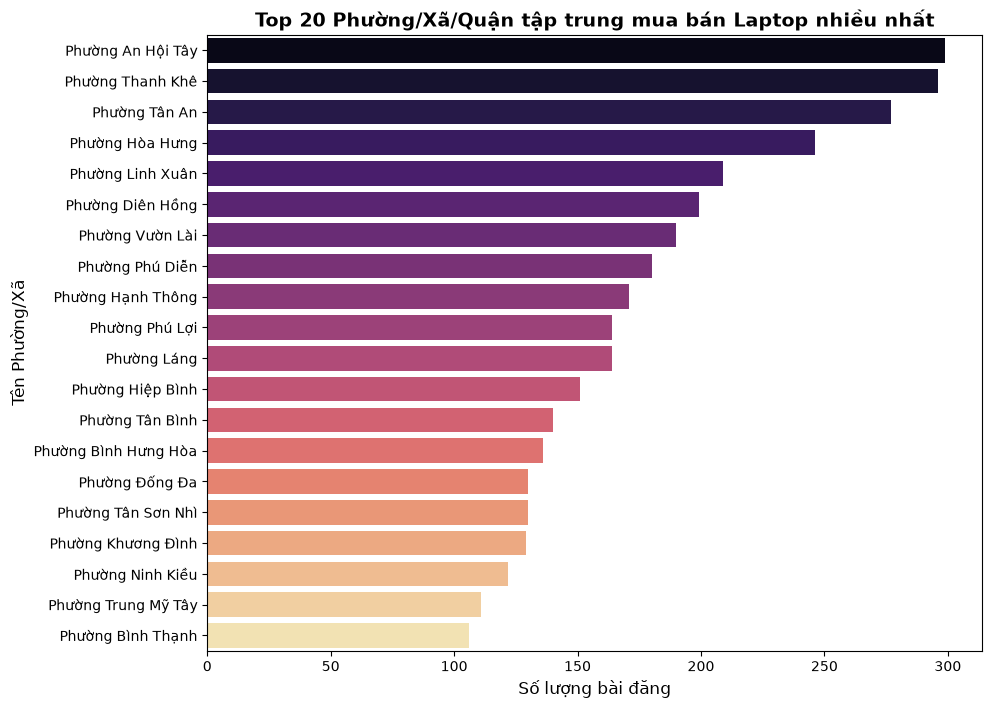

In [97]:
ward_counts = df['ward_name'].value_counts(dropna=False).head(20)

plt.figure(figsize=(10, 8))
sns.barplot(x=ward_counts.values, y=ward_counts.index.astype(str), palette='magma', orient='h')
plt.title('Top 20 Phường/Xã/Quận tập trung mua bán Laptop nhiều nhất', fontsize=14, fontweight='bold')
plt.xlabel('Số lượng bài đăng', fontsize=12)
plt.ylabel('Tên Phường/Xã', fontsize=12)
plt.show()

## Origin (Nguồn gốc/Xuất xứ)

### Origin type (Loại nguồn gốc)

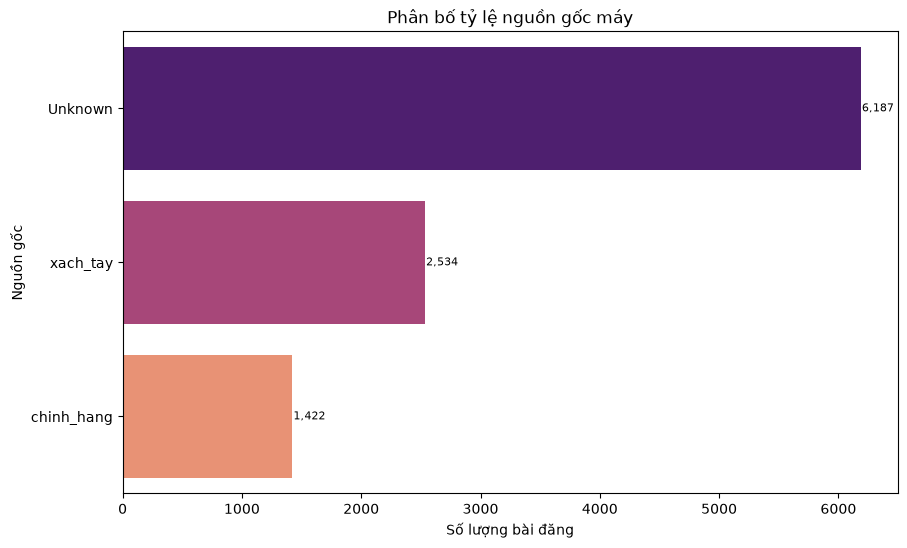

In [98]:
plt.figure(figsize=(10, 6))
origin_counts = df['origin_type'].fillna('Unknown').value_counts()
sns.barplot(x=origin_counts.values, y=origin_counts.index, palette='magma')
plt.xlabel("Số lượng bài đăng")
plt.ylabel("Nguồn gốc")
plt.title("Phân bố tỷ lệ nguồn gốc máy")

for i, v in enumerate(origin_counts):
    plt.text(v + 10, i, f"{v:,.0f}", color='black', va='center', fontsize=8)
    
plt.show()

In [99]:
null_origin_type = df['origin_type'].isnull().sum()
print(f"Số bài đăng khuyết dữ liệu xuất xứ: {null_origin_type}, chiếm {(null_origin_type / df.shape[0])*100:.2f}% tổng bài đăng")

Số bài đăng khuyết dữ liệu xuất xứ: 6187, chiếm 61.00% tổng bài đăng


### Origin country (Quốc gia)

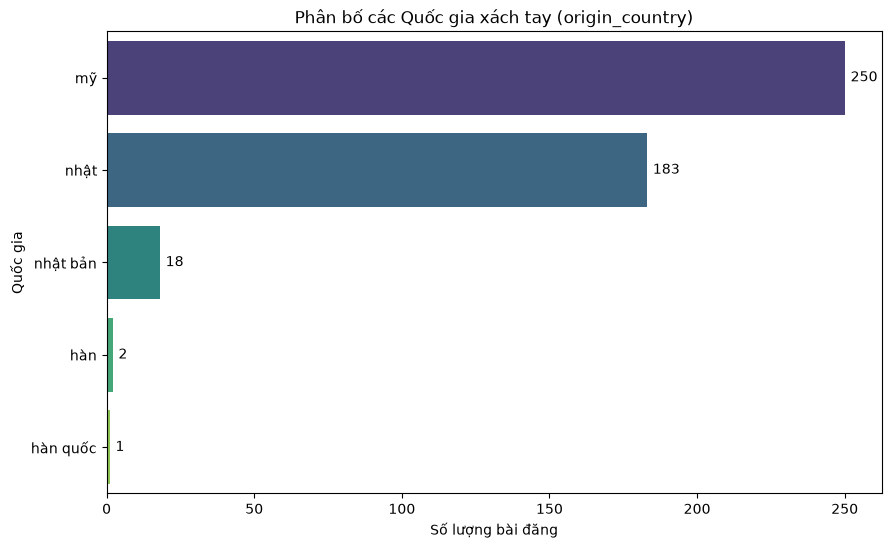

In [100]:
plt.figure(figsize=(10, 6))
country_counts = df['origin_country'].dropna().value_counts()
sns.barplot(x=country_counts.values, y=country_counts.index, palette='viridis')
plt.title('Phân bố các Quốc gia xách tay (origin_country)')
plt.xlabel('Số lượng bài đăng')
plt.ylabel('Quốc gia')

for i, v in enumerate(country_counts.values):
    plt.text(v + 2, i, str(v), color='black', va='center')
    
plt.show()

In [101]:
null_origin_country = df['origin_country'].isnull().sum()
print(f"Số bài đăng khuyết thông tin quốc gia xuất xứ: {null_origin_country}, chiếm {(null_origin_country / df.shape[0])*100:.2f} tổng số bài đăng")

Số bài đăng khuyết thông tin quốc gia xuất xứ: 9689, chiếm 95.52 tổng số bài đăng


## Warranty (Bảo hành)

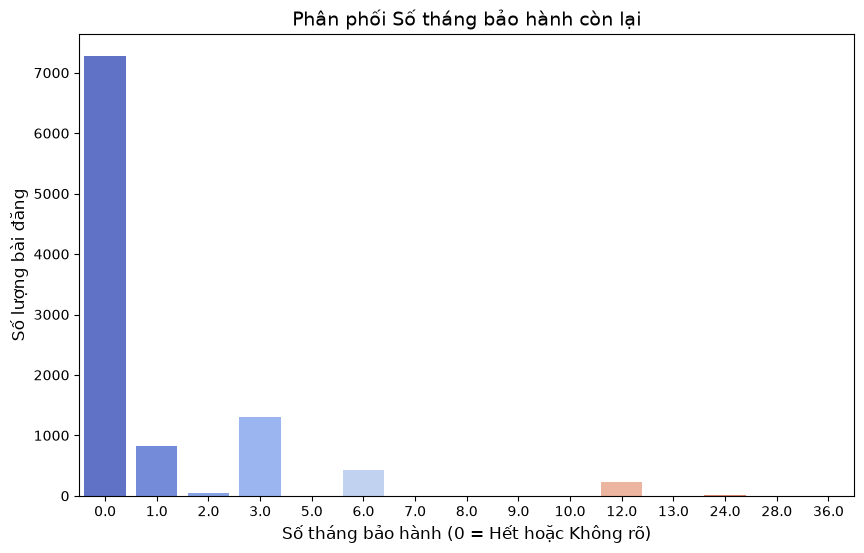

In [102]:
plt.figure(figsize=(10, 6))
df['warranty_months_eda'] = df['warranty_months'].fillna(0)
months_counts = df['warranty_months_eda'].value_counts().sort_index()
sns.barplot(x=months_counts.index, y=months_counts.values, palette='coolwarm')
plt.title('Phân phối Số tháng bảo hành còn lại', fontsize=14)
plt.xlabel('Số tháng bảo hành (0 = Hết hoặc Không rõ)', fontsize=12)
plt.ylabel('Số lượng bài đăng', fontsize=12)
plt.show()

In [103]:
has_warranty = (df['warranty_months_eda'] > 0).sum()
print(f"Tỷ lệ máy CÓ bảo hành: {has_warranty / len(df) * 100:.1f}%")

Tỷ lệ máy CÓ bảo hành: 28.2%


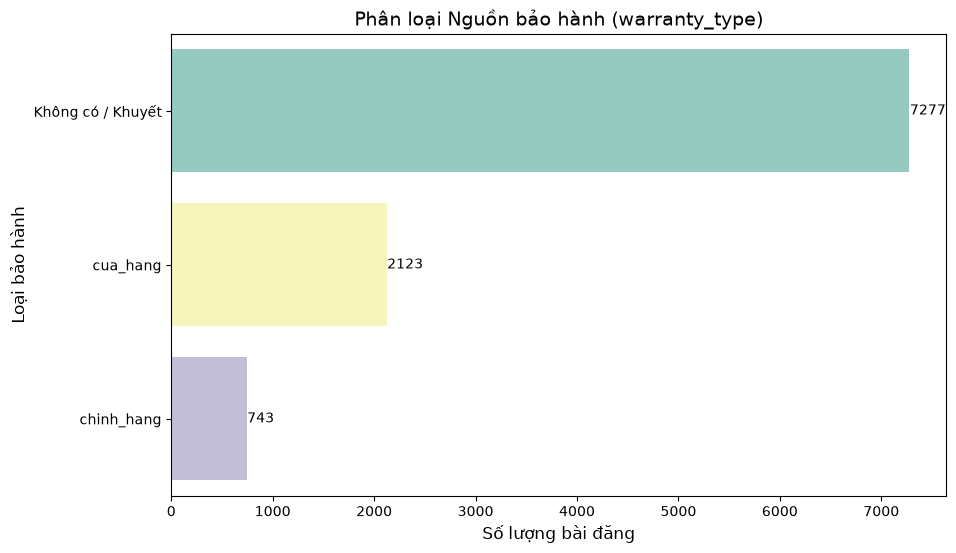

In [104]:
plt.figure(figsize=(10, 6))
type_counts = df['warranty_type'].fillna('Không có / Khuyết').value_counts()
sns.barplot(x=type_counts.values, y=type_counts.index, palette='Set3')
plt.title('Phân loại Nguồn bảo hành (warranty_type)', fontsize=14)
plt.xlabel('Số lượng bài đăng', fontsize=12)
plt.ylabel('Loại bảo hành', fontsize=12)

for i, v in enumerate(type_counts.values):
    plt.text(v + 5, i, str(v), color='black', va='center')
    
plt.show()

In [105]:
anomalies = df[(df['warranty_months_eda'] > 0) & (df['warranty_type'].isna())]
print(f"Số ca mâu thuẫn (Có tháng nhưng không rõ loại bảo hành): {len(anomalies)}")

Số ca mâu thuẫn (Có tháng nhưng không rõ loại bảo hành): 1440


## Year Production

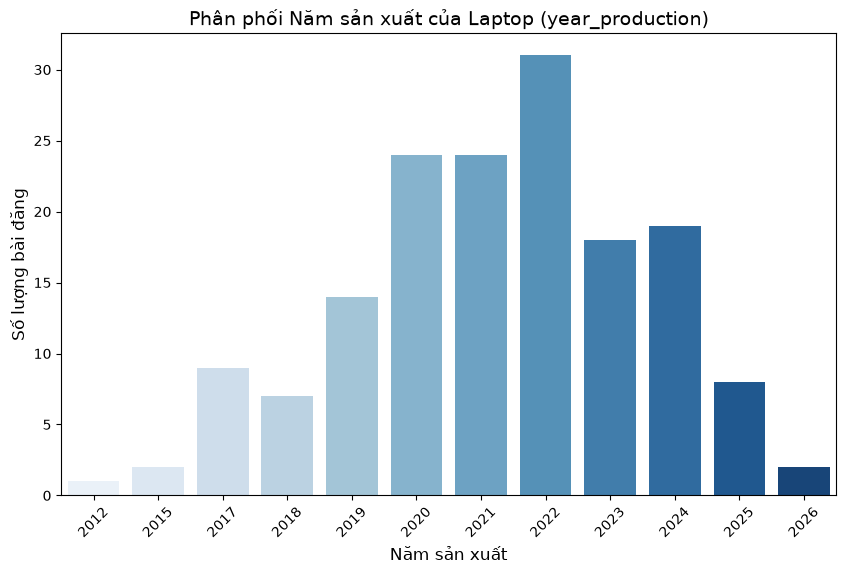

In [106]:
plt.figure(figsize=(10, 6))
valid_prod_years = df['year_production'].dropna().astype(int)
prod_counts = valid_prod_years.value_counts().sort_index()
sns.barplot(x=prod_counts.index, y=prod_counts.values, palette='Blues')
plt.title('Phân phối Năm sản xuất của Laptop (year_production)', fontsize=14)
plt.xlabel('Năm sản xuất', fontsize=12)
plt.ylabel('Số lượng bài đăng', fontsize=12)
plt.xticks(rotation=45)
plt.show()

In [107]:
outliers = valid_prod_years[(valid_prod_years < 2012) | (valid_prod_years > 2026)]
print(f"Phát hiện {len(outliers)} bài đăng có năm sản xuất vô lý hoặc quá cũ:")
print(outliers.unique())

Phát hiện 0 bài đăng có năm sản xuất vô lý hoặc quá cũ:
[]


## Year Purchase

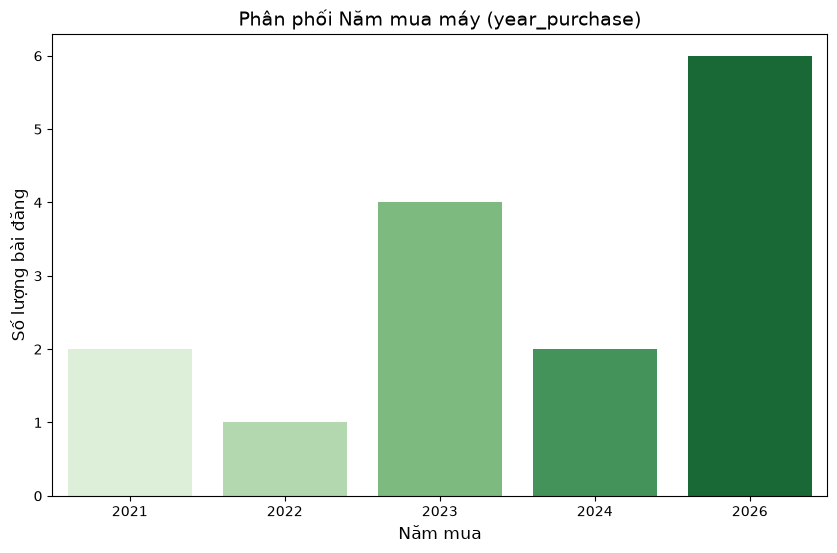

In [108]:
plt.figure(figsize=(10, 6))
valid_purch_years = df['year_purchase'].dropna().astype(int)
purch_counts = valid_purch_years.value_counts().sort_index()
sns.barplot(x=purch_counts.index, y=purch_counts.values, palette='Greens')
plt.title('Phân phối Năm mua máy (year_purchase)', fontsize=14)
plt.xlabel('Năm mua', fontsize=12)
plt.ylabel('Số lượng bài đăng', fontsize=12)
plt.show()

In [109]:
missing_purch = df['year_purchase'].isna().sum()
print(f"Số lượng bài đăng không ghi năm mua: {missing_purch} ({missing_purch/len(df)*100:.2f}%)")

Số lượng bài đăng không ghi năm mua: 10128 (99.85%)


## Bundles

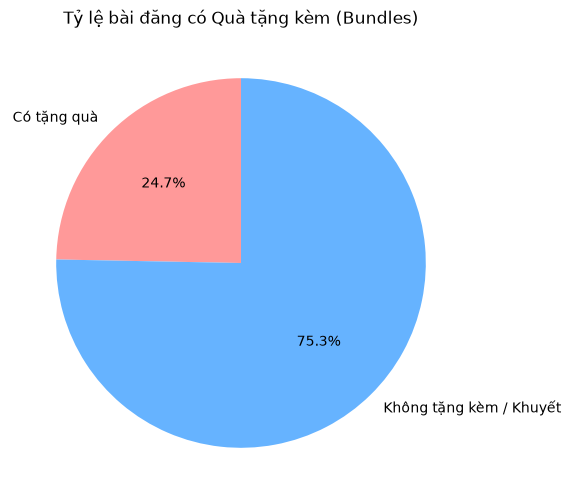

In [110]:
plt.figure(figsize=(6, 6))
has_bundle = df['bundles'].notna().sum()
no_bundle = df['bundles'].isna().sum()
plt.pie([has_bundle, no_bundle], labels=['Có tặng quà', 'Không tặng kèm / Khuyết'], autopct='%1.1f%%', colors=['#ff9999','#66b3ff'], startangle=90)
plt.title('Tỷ lệ bài đăng có Quà tặng kèm (Bundles)')
plt.show()

In [111]:
valid_bundles = df['bundles'].dropna().astype(str).str.lower()
split_bundles = valid_bundles.str.split(r'\s*,\s*|\s*\+\s*')
individual_items = split_bundles.explode().str.strip()
individual_items = individual_items[individual_items != '']
top_bundles = individual_items.value_counts().head(15)
print("Top 15 quà tặng kèm phổ biến nhất:")
print(top_bundles)

Top 15 quà tặng kèm phổ biến nhất:
bundles
túi chống sốc                                                                                                                                                                                                                                                                                                                                        306
chuột không dây                                                                                                                                                                                                                                                                                                                                      244
chuột                                                                                                                                                                                                                                                                      

---
# BIVARIATE & MULTIVARIATE ANALYSIS
---

## Giá theo Thương hiệu & Phân khúc (Brand & Production Line)

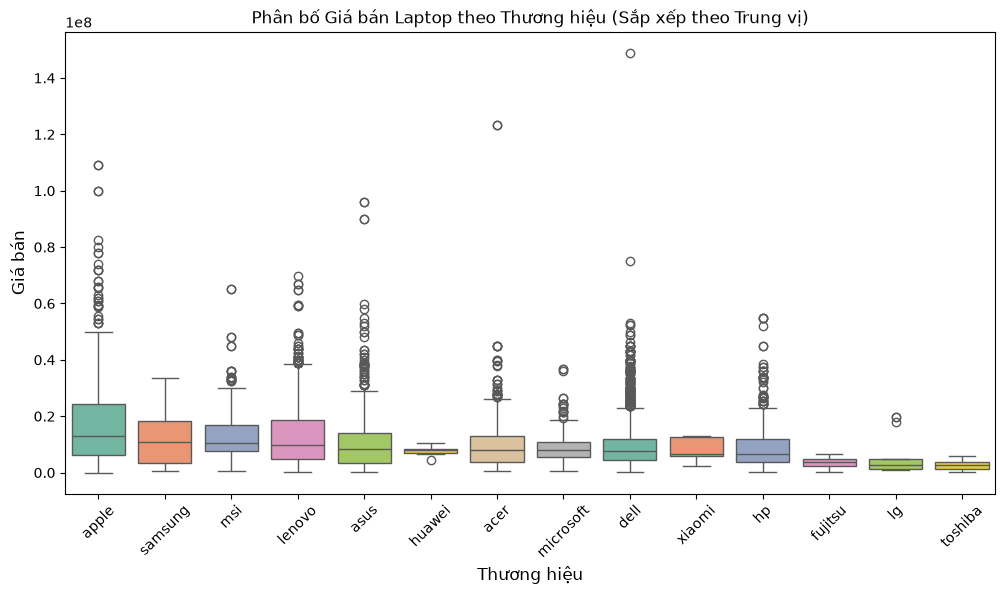

In [112]:
order = df.groupby("brand_name")["target_price"].median().sort_values(ascending=False).index

plt.figure(figsize=(12, 6))
sns.boxplot(x='brand_name', y='target_price', data=df, order=order, palette='Set2')
plt.title("Phân bố Giá bán Laptop theo Thương hiệu (Sắp xếp theo Trung vị)")
plt.xlabel("Thương hiệu", fontsize=12)
plt.ylabel("Giá bán", fontsize=12)
plt.xticks(rotation=45)
plt.show()

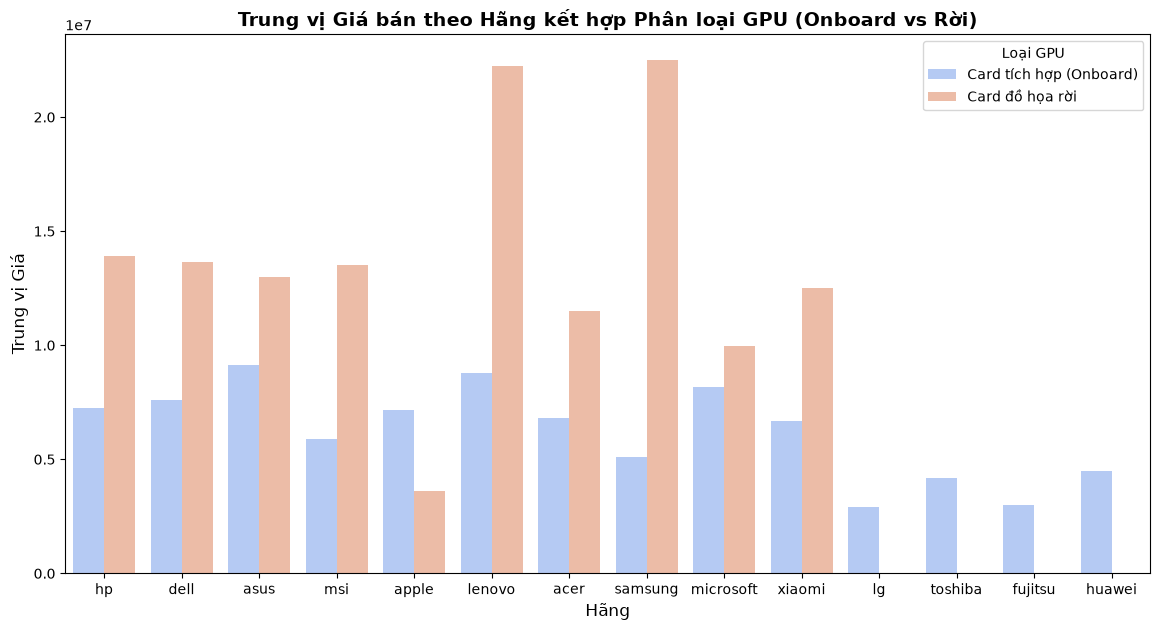

In [113]:
plt.figure(figsize=(14, 7))
sns.barplot(x='brand_name', y='target_price', hue='gpu_type', data=df[df['gpu_type'].notna()], estimator=np.median, ci=None, palette='coolwarm')
plt.title("Trung vị Giá bán theo Hãng kết hợp Phân loại GPU (Onboard vs Rời)", fontsize=14, fontweight='bold')
plt.xlabel("Hãng", fontsize=12)
plt.ylabel("Trung vị Giá", fontsize=12)
plt.legend(title="Loại GPU", labels=["Card tích hợp (Onboard)", "Card đồ họa rời"])
plt.show()

## Tác động của cấu hình máy lên giá (Hardware Configuration Impact)

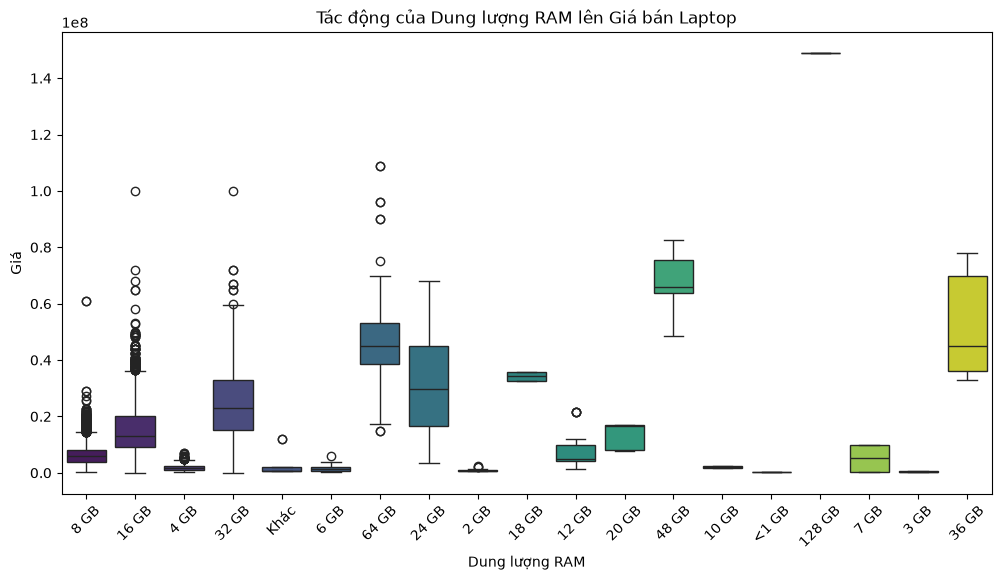

In [114]:
plt.figure(figsize=(12, 6))
valid_ram = df.dropna(subset=['raw_ram', 'target_price']).copy()
sns.boxplot(x='raw_ram', y='target_price', data=valid_ram, palette='viridis')
plt.title("Tác động của Dung lượng RAM lên Giá bán Laptop")
plt.xticks(rotation=45)
plt.xlabel("Dung lượng RAM")
plt.ylabel("Giá")
plt.show()

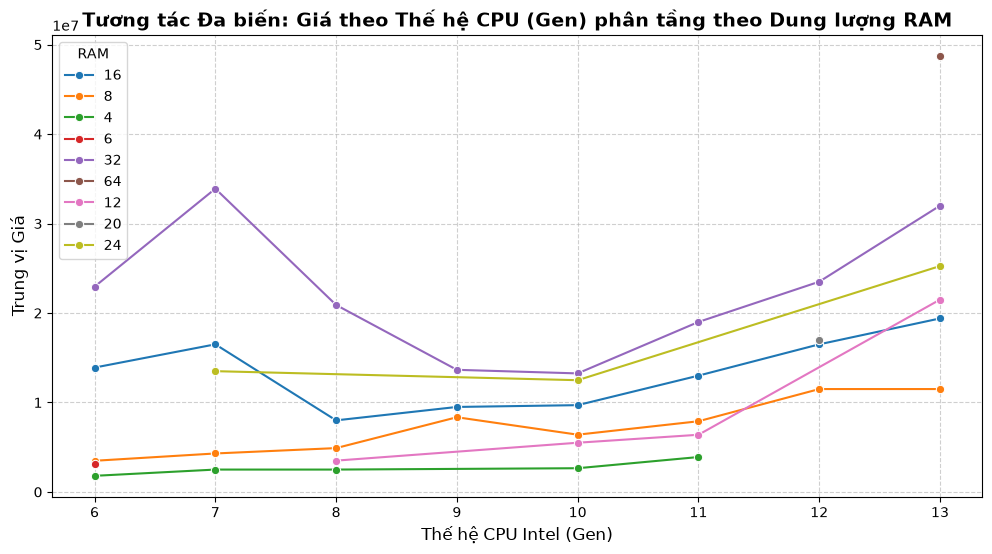

In [115]:
df_gen = df.copy()
df_gen['cpu_gen'] = pd.to_numeric(df_gen['cpu_gen'], errors='coerce')
df_gen['raw_ram'] = pd.to_numeric(
    df_gen['raw_ram'].astype('string').str.extract(r'(\d+(?:\.\d+)?)', expand=False),
    errors='coerce'
)

df_gen = df_gen.loc[
    df_gen['cpu_gen'].between(6, 13)
    & df_gen['raw_ram'].notna()
    & df_gen['target_price'].notna()
].copy()
df_gen['raw_ram'] = df_gen['raw_ram'].astype(int).astype(str)

plt.figure(figsize=(12, 6))
sns.lineplot(x='cpu_gen', y='target_price', hue='raw_ram', data=df_gen, marker='o', palette='tab10', estimator=np.median, ci=None)
plt.title("Tương tác Đa biến: Giá theo Thế hệ CPU (Gen) phân tầng theo Dung lượng RAM", fontsize=14, fontweight='bold')
plt.xlabel("Thế hệ CPU Intel (Gen)", fontsize=12)
plt.ylabel("Trung vị Giá", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(title="RAM")
plt.show()

## Tác động của Độ mới & Bảo hành lên Giá (Condition & Warranty)

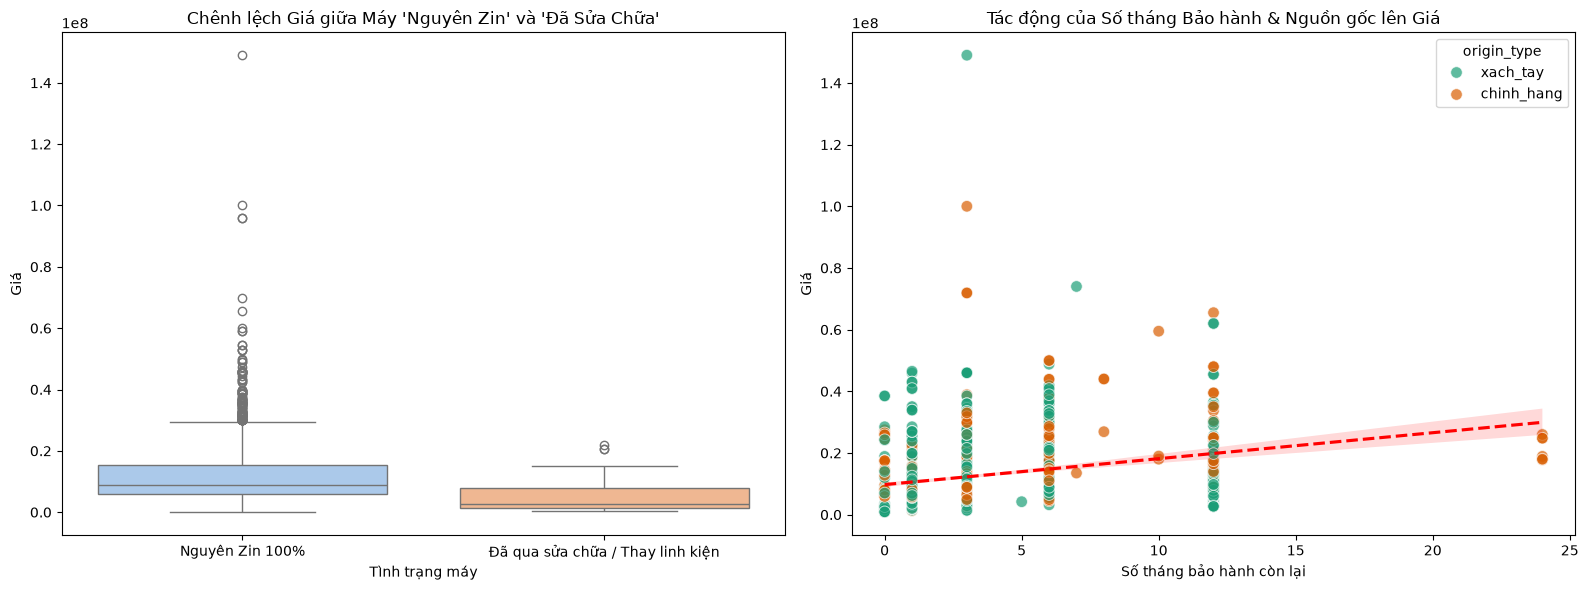

In [116]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

repair_order = ['original', 'repaired']
sns.boxplot(ax=axes[0], x='repair_status', y='target_price', data=df[df['repair_status'].isin(repair_order)], palette='pastel')
axes[0].set_title("Chênh lệch Giá giữa Máy 'Nguyên Zin' và 'Đã Sửa Chữa'")
axes[0].set_xlabel("Tình trạng máy")
axes[0].set_ylabel("Giá")
axes[0].set_xticklabels(["Nguyên Zin 100%", "Đã qua sửa chữa / Thay linh kiện"])

# 3.2 Multivariate: Thời hạn bảo hành kết hợp Nguồn gốc (Chính hãng vs Xách tay)
valid_origin = df.loc[
    df['origin_type'].notna()
    & df['warranty_months'].between(0, 24)
    & df['target_price'].notna()
].copy()

sns.scatterplot(
    ax=axes[1], x='warranty_months', y='target_price', hue='origin_type',
    data=valid_origin, alpha=0.7, s=70, palette='Dark2'
)
sns.regplot(
    ax=axes[1], x='warranty_months', y='target_price', 
    data=valid_origin, scatter=False, color='red', line_kws={'linestyle': '--'}
)
axes[1].set_title("Tác động của Số tháng Bảo hành & Nguồn gốc lên Giá")
axes[1].set_xlabel("Số tháng bảo hành còn lại")
axes[1].set_ylabel("Giá")

plt.tight_layout()
plt.show()

## Tương quan (Correlation)

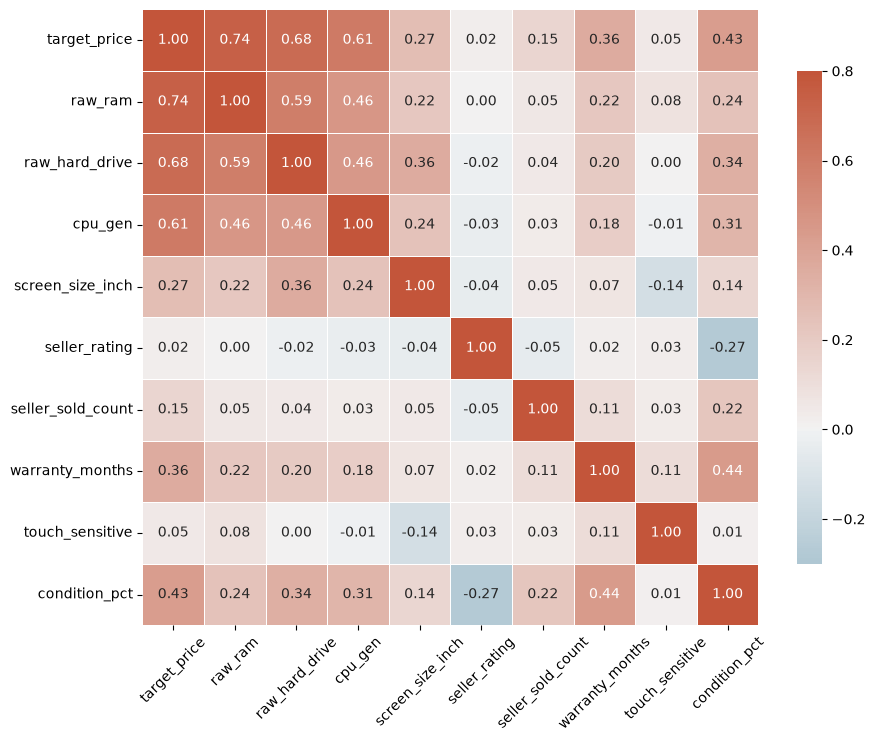

In [117]:
numeric_cols = [
    'target_price', 'raw_ram', 'raw_hard_drive', 'cpu_gen', 
    'screen_size_inch', 'seller_rating', 'seller_sold_count', 
    'warranty_months', 'touch_sensitive', 'condition_pct'
]
corr_data = df[numeric_cols].copy()

# Extract numeric capacities from values such as "8 GB" and "256 GB".
corr_data['raw_ram'] = pd.to_numeric(corr_data['raw_ram'].astype('string').str.extract(r'(\d+(?:\.\d+)?)', expand=False), errors='coerce')

# Convert storage capacities to GB; unparseable values become NaN.
storage = df['raw_hard_drive'].astype('string')
corr_data['raw_hard_drive'] = pd.to_numeric(storage.str.extract(r'(\d+(?:\.\d+)?)', expand=False), errors='coerce')
corr_data.loc[storage.str.contains(r'\bTB\b', case=False, na=False),'raw_hard_drive'] *= 1024

# Ensure every correlation input is numeric.
for col in numeric_cols:
    corr_data[col] = pd.to_numeric(corr_data[col], errors='coerce')

corr_spearman = corr_data.corr(method='spearman')

plt.figure(figsize=(10, 8))
#mask = np.triu(np.ones_like(corr_spearman, dtype=bool))

cmap = sns.diverging_palette(230, 20, as_cmap=True)
sns.heatmap(corr_spearman, cmap=cmap, vmin=-0.3, vmax=0.8, center=0, square=True, linewidths=.5, cbar_kws={"shrink": .8}, annot=True, fmt=".2f")
#plt.title("Ma trận Tương quan Spearman giữa Giá và các Đặc trưng Định lượng")
plt.xticks(rotation=45)
plt.show()

In [118]:
price_corr = corr_spearman['target_price'].drop('target_price').sort_values(ascending=False)
print("=== HỆ SỐ TƯƠNG QUAN VỚI GIÁ BÁN (TARGET_PRICE) ===")
print(price_corr.round(3))

=== HỆ SỐ TƯƠNG QUAN VỚI GIÁ BÁN (TARGET_PRICE) ===
raw_ram              0.738
raw_hard_drive       0.681
cpu_gen              0.608
condition_pct        0.427
warranty_months      0.361
screen_size_inch     0.265
seller_sold_count    0.150
touch_sensitive      0.047
seller_rating        0.020
Name: target_price, dtype: float64
